# LAB 08 — Pretrained Transformers & BERT Fine-Tuning (báo cáo chính)

Sentiment classification nhị phân với `distilbert-base-uncased`. Notebook này chứa **toàn bộ** nội dung: lý thuyết/tính toán, prediction, tokenization, code lõi, Exp 1–5, application, error & confidence analysis, kiểm chứng prediction, Q1–Q6, reflection, AI-assisted code. Mọi bảng/hình hiển thị inline; mọi con số trong văn bản phân tích được sinh bằng f-string từ kết quả (`results.csv`, `runs/*/result.json`) chứ không gõ tay.

**Chạy lại.** Mỗi cấu hình (31 run, ~2 giờ train trên RTX 3050) đã được cache ở `runs/<tên>/`. `RUN_TRAINING = False` (mặc định): chỉ nạp kết quả/dự đoán đã lưu, không train. Đặt biến môi trường `LAB08_RUN_TRAINING=1` để train lại những run chưa có cache khớp cấu hình.

Thứ tự: 0 Reproducibility → 1 Theory & Calculation → 2 Prediction → 3 Tokenization → 4 Core implementation → 5 Dữ liệu → 6 Chạy lưới thí nghiệm & ghi `results.csv` → 7–11 Exp 1–5 → 12 Application → 13 Confidence → 14 Error analysis → 15 Kiểm chứng prediction → 16 Q1–Q6 → 17 Reflection → 18 AI-assisted code.

In [1]:
import pandas as pd  # Windows: import pandas truoc torch
import numpy as np, json, sys, time, os, math, inspect, re
from pathlib import Path
import torch
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import display, Markdown, Image
sys.path.insert(0, ".")
import pretrained_classification as pc

RUN_TRAINING = os.environ.get("LAB08_RUN_TRAINING", "0") == "1"   # False: chi nap cache, khong train
pc.set_seed(pc.SEED)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", None)

def md_(s): display(Markdown(s))
def save_show(fig, path):
    """savefig -> plt.show() -> chen lai anh da luu (dam bao hien ca khi mo tren GitHub/nbviewer)."""
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"*Ảnh đã lưu: `{path}` (đọc lại từ đĩa)*")); display(Image(filename=path))

print("RUN_TRAINING =", RUN_TRAINING)
print("hardware:", pc.hardware_info())

C:\Users\Admin\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RUN_TRAINING = False
hardware: {'device': 'cuda', 'platform': 'Windows-11-10.0.26200-SP0', 'python': '3.14.5', 'torch': '2.12.0+cu126', 'transformers': '5.12.1', 'gpu': 'NVIDIA GeForce RTX 3050 6GB Laptop GPU', 'gpu_vram_mb': 6144}


## 0. Bảng reproducibility (mục 23)
Đọc từ `runs/<tên>/run_config.json` của **từng** run trong lưới (31 run).

In [2]:
grid = pc.build_grid()
rows = []
for name in grid:
    rc = json.loads((pc.RUNS_DIR / name / "run_config.json").read_text(encoding="utf-8"))
    rows.append({"run": name, "model": rc["Model"], "train → test": f"{rc['cfg']['train_domain']} → {','.join(rc['cfg']['test_domains'])}",
                 "train / val / test": f"{rc['Train split'].split(' ')[0]} / {rc['Validation split'].split(' ')[0]} / " + " & ".join(s.split(' ')[0] for s in rc["Test split"].values()),
                 "max_len": rc["Max sequence length"], "batch": rc["Batch size"], "lr": rc["Learning rate"], "epochs": rc["Epochs"],
                 "seed": rc["Random seed"], "train time (s)": rc["Training time (s)"], "peak mem (MB)": rc["Peak memory (MB)"]})
display(pd.DataFrame(rows))
rc = json.loads((pc.RUNS_DIR / pc.run_name("ft") / "run_config.json").read_text(encoding="utf-8"))
md_("**Phần chung cho mọi run** (từ `run_config.json` của run chính):")
display(pd.DataFrame({"giá trị": {"Tokenizer": rc["Tokenizer"], "Dataset (A)": rc["Dataset"], "Optimizer": rc["Optimizer"], "Hardware": rc["Hardware"]["gpu"],
       "Python / torch / transformers": f"{rc['Hardware']['python']} / {rc['Hardware']['torch']} / {rc['Hardware']['transformers']}", "Model params": f"{rc['params_total']:,}"}}))

,run,model,train → test,train / val / test,max_len,batch,lr,epochs,seed,train time (s),peak mem (MB)
0,lrsweep_scratch_lr5e-05,"distilbert-base-uncased (random init, same architecture via AutoConfig)",A → A,7970 / 7904 / 10000,128,32,0.00005,3,42,135.0,1704.0
1,lrsweep_scratch_lr0.0001,"distilbert-base-uncased (random init, same architecture via AutoConfig)",A → A,7970 / 7904 / 10000,128,32,0.00010,3,42,126.3,1706.5
2,lrsweep_scratch_lr0.0003,"distilbert-base-uncased (random init, same architecture via AutoConfig)",A → A,7970 / 7904 / 10000,128,32,0.00030,3,42,125.2,1706.5
3,ft_A_len128_frac1.0_s42,distilbert-base-uncased,"A → A,B",31879 / 7904 / 10000 & 10000,128,32,0.00002,3,42,497.1,1704.0
4,scratch_A_len128_frac1.0_s42,"distilbert-base-uncased (random init, same architecture via AutoConfig)","A → A,B",31879 / 7904 / 10000 & 10000,128,32,0.00005,3,42,476.6,1706.5
5,frozen_A_len128_frac1.0_s42,distilbert-base-uncased [encoder frozen],A → A,31879 / 7904 / 10000,128,32,0.00100,3,42,124.8,608.3
6,ft_A_len64_frac1.0_s42,distilbert-base-uncased,A → A,31879 / 7904 / 10000,64,32,0.00002,3,42,326.9,1312.9
7,ft_A_len256_frac1.0_s42,distilbert-base-uncased,A → A,31879 / 7904 / 10000,256,32,0.00002,3,42,863.0,2532.2
8,ft_B_len128_frac1.0_s42,distilbert-base-uncased,"B → B,A",31879 / 7904 / 10000 & 10000,128,32,0.00002,3,42,472.8,1706.5
9,ft_A_len128_frac0.1_s42,distilbert-base-uncased,A → A,3189 / 7904 / 10000,128,32,0.00002,3,42,47.3,1706.3


**Phần chung cho mọi run** (từ `run_config.json` của run chính):

,giá trị
Tokenizer,"distilbert-base-uncased (WordPiece, same checkpoint)"
Dataset (A),"train: IMDb (LAB 05 split, seed 42, stratified val 20% + duplicate-leak cleaning)"
Optimizer,"AdamW(weight_decay=0.01) + linear warmup(0.1)/decay, grad_clip=1.0, fp16=True"
Hardware,NVIDIA GeForce RTX 3050 6GB Laptop GPU
Python / torch / transformers,3.14.5 / 2.12.0+cu126 / 5.12.1
Model params,"66,364,418"


## 1. Theory & Calculation

### 1.1 MLM loss (mục 9)
Câu `The cat [MASK] fish.`, token đúng $y=\text{eats}$. Model dự đoán: cat 0.10, dog 0.05, **eats 0.70**, fish 0.15 (tổng = 1). Một vị trí bị mask nên $M=\{i\}$:
$$\mathcal{L}_{MLM} = -\sum_{i\in M}\log P(y_i\mid x) = -\log P(\text{eats}\mid x)$$
Tính với $P(\text{eats}) \in \{0.70,\ 0.95,\ 0.01\}$ (logarit tự nhiên, đơn vị nat):

In [3]:
import math
P_VALS = (0.70, 0.95, 0.01)
mlm = pd.DataFrame({"P(eats)": P_VALS, "L = -ln P": [-math.log(p) for p in P_VALS]})
mlm["so với L(0.70)"] = mlm["L = -ln P"] / mlm.loc[0, "L = -ln P"]
display(mlm.round(6))
print("tong xac suat dau vao:", 0.10 + 0.05 + 0.70 + 0.15, "| tham chieu doan deu tren vocab 30,522: ln V =", round(math.log(30522), 3))

,P(eats),L = -ln P,so với L(0.70)
0,0.70,0.356675,1.000000
1,0.95,0.051293,0.143810
2,0.01,4.605170,12.911392


tong xac suat dau vao: 1.0 | tham chieu doan deu tren vocab 30,522: ln V = 10.326


In [4]:
L70, L95, L01 = (-math.log(p) for p in P_VALS)
md_(f"""**Giải thích sự thay đổi.**

1. $P=0.95$: model gần như chắc chắn đúng → loss $={L95:.3f}$ (so với {L70:.3f} ở $P=0.70$: giảm {L70 - L95:.3f}, nhỏ hơn {L70 / L95:.1f} lần). Lợi ích biên giảm dần: từ 0.95 lên 0.99 chỉ giảm thêm {L95 + math.log(0.99):.3f}.
2. $P=0.01$: model gần như chắc chắn **sai** → loss $={L01:.3f}$ (tăng {L01 - L70:.3f}, lớn hơn {L01 / L70:.1f} lần so với 0.70). $-\\log P$ **không đối xứng**: phạt rất nặng khi xác suất đáp án đúng $\\to 0$ ($L\\to\\infty$), nhẹ khi đã đúng. Mức "đoán đều" trên 30,522 token là $\\ln V={math.log(30522):.2f}$, nên 4.605 vẫn tốt hơn đoán đều nhưng tệ hơn nhiều so với 0.357.
3. **Vì sao cross-entropy phù hợp với MLM?** (i) MLM là *phân loại đa lớp* trên $|V|\\approx 30k$ token tại mỗi vị trí mask; CE với nhãn one-hot chính là negative log-likelihood của token thật ⇒ tối thiểu hoá CE = maximum likelihood. (ii) Là proper scoring rule: cực tiểu khi phân phối dự đoán trùng phân phối thật. (iii) Gradient theo logit $z_k$ là $p_k-\\mathbb{{1}}[k=y]$: sai nhiều thì gradient lớn, đúng rồi thì $\\approx 0$ → học ổn định. (iv) Nhiều vị trí mask: loss cộng theo $i\\in M$, mỗi vị trí đóng góp độc lập đúng như công thức của đề.""")

**Giải thích sự thay đổi.**

1. $P=0.95$: model gần như chắc chắn đúng → loss $=0.051$ (so với 0.357 ở $P=0.70$: giảm 0.305, nhỏ hơn 7.0 lần). Lợi ích biên giảm dần: từ 0.95 lên 0.99 chỉ giảm thêm 0.041.
2. $P=0.01$: model gần như chắc chắn **sai** → loss $=4.605$ (tăng 4.248, lớn hơn 12.9 lần so với 0.70). $-\log P$ **không đối xứng**: phạt rất nặng khi xác suất đáp án đúng $\to 0$ ($L\to\infty$), nhẹ khi đã đúng. Mức "đoán đều" trên 30,522 token là $\ln V=10.33$, nên 4.605 vẫn tốt hơn đoán đều nhưng tệ hơn nhiều so với 0.357.
3. **Vì sao cross-entropy phù hợp với MLM?** (i) MLM là *phân loại đa lớp* trên $|V|\approx 30k$ token tại mỗi vị trí mask; CE với nhãn one-hot chính là negative log-likelihood của token thật ⇒ tối thiểu hoá CE = maximum likelihood. (ii) Là proper scoring rule: cực tiểu khi phân phối dự đoán trùng phân phối thật. (iii) Gradient theo logit $z_k$ là $p_k-\mathbb{1}[k=y]$: sai nhiều thì gradient lớn, đúng rồi thì $\approx 0$ → học ổn định. (iv) Nhiều vị trí mask: loss cộng theo $i\in M$, mỗi vị trí đóng góp độc lập đúng như công thức của đề.

### 1.2 Attention mask `[1, 1, 1, 1, 1, 0, 0]` (mục 7)
Chuỗi `[CLS] the cat eats fish [PAD] [PAD]` → mask `[1,1,1,1,1,0,0]`: 5 vị trí hợp lệ, 2 vị trí padding. Với một query có 7 điểm attention $s=[2,1,0,1,0.5,3,3]$ (hai PAD cuối cố ý có điểm cao), mask đặt $s_j=-\infty$ nơi mask $=0$ **trước** softmax.

In [5]:
s = np.array([2.0, 1.0, 0.0, 1.0, 0.5, 3.0, 3.0]); mask = np.array([1, 1, 1, 1, 1, 0, 0])
softmax = lambda x: np.exp(x - x.max()) / np.exp(x - x.max()).sum()
no_mask, with_mask = softmax(s), softmax(np.where(mask == 1, s, -np.inf))
att = pd.DataFrame({"không mask": no_mask, "có mask": with_mask}, index=["w1", "w2", "w3", "w4", "w5", "PAD", "PAD"]).T
att["tổng khối lượng trên PAD"] = [no_mask[5:].sum(), with_mask[5:].sum()]
display(att.round(4))

# kiem chung tren model that: unpadded vs padded+mask vs padded KHONG mask
from transformers import AutoModel, AutoTokenizer
tok0 = AutoTokenizer.from_pretrained(pc.MODEL_NAME); enc0 = AutoModel.from_pretrained(pc.MODEL_NAME).eval()
a = tok0("the cat eats fish", return_tensors="pt"); b = tok0("the cat eats fish", padding="max_length", max_length=7, return_tensors="pt")
print("tokens (khong pad):", tok0.convert_ids_to_tokens(a["input_ids"][0]), "mask", a["attention_mask"][0].tolist())
print("tokens (pad to 7) :", tok0.convert_ids_to_tokens(b["input_ids"][0]), "mask", b["attention_mask"][0].tolist())
with torch.no_grad():
    ha = enc0(**a).last_hidden_state; hb = enc0(**b).last_hidden_state; hn = enc0(input_ids=b["input_ids"]).last_hidden_state
n = a["input_ids"].shape[1]
d_mask, d_nomask = (ha - hb[:, :n]).abs().max().item(), (ha - hn[:, :n]).abs().max().item()
cos = torch.cosine_similarity(ha[0, 0], hn[0, 0], dim=0).item()
print(f"max|h_unpadded - h_padded+mask| = {d_mask:.4f} | max|h_unpadded - h_padded KHONG mask| = {d_nomask:.4f} | cosine([CLS]) = {cos:.4f}")
md_(f"**Kết luận:** không mask, hai vị trí PAD chiếm {no_mask[5:].sum() * 100:.1f}% trọng số attention; có mask, trọng số PAD $=0$ và 5 token thật được chuẩn hoá lại (tổng $=1$). Trên model thật, thêm padding **kèm mask** không đổi hidden state (sai khác {d_mask:.1f}); quên truyền mask làm sai khác tăng lên {d_nomask:.3f} — vì vậy `PretrainedClassifier.forward` luôn truyền `attention_mask`.")
del enc0

,w1,w2,w3,w4,w5,PAD,PAD,tổng khối lượng trên PAD
không mask,0.1328,0.0489,0.0180,0.0489,0.0296,0.361,0.361,0.7219
có mask,0.4775,0.1757,0.0646,0.1757,0.1065,0.000,0.000,0.0000



Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 8649.83it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokens (khong pad): ['[CLS]', 'the', 'cat', 'eats', 'fish', '[SEP]'] mask [1, 1, 1, 1, 1, 1]
tokens (pad to 7) : ['[CLS]', 'the', 'cat', 'eats', 'fish', '[SEP]', '[PAD]'] mask [1, 1, 1, 1, 1, 1, 0]
max|h_unpadded - h_padded+mask| = 0.0000 | max|h_unpadded - h_padded KHONG mask| = 0.3001 | cosine([CLS]) = 0.9932


**Kết luận:** không mask, hai vị trí PAD chiếm 72.2% trọng số attention; có mask, trọng số PAD $=0$ và 5 token thật được chuẩn hoá lại (tổng $=1$). Trên model thật, thêm padding **kèm mask** không đổi hidden state (sai khác 0.0); quên truyền mask làm sai khác tăng lên 0.300 — vì vậy `PretrainedClassifier.forward` luôn truyền `attention_mask`.

## 2. Prediction (viết trước mọi thí nghiệm)
Chép **nguyên văn** từ `prediction.md` (không sửa). Phần kiểm chứng đối chiếu ở mục 15.

---

# Prediction

## P1: Pretrained fine-tuned tốt hơn Transformer nhỏ train from scratch trên IMDb?
Prediction: Có, tốt hơn rõ rệt.
Reason: Pretrained đã học cú pháp/ngữ nghĩa và embedding ngữ cảnh từ corpus lớn qua MLM; model from scratch phải học cả biểu diễn lẫn task chỉ từ vài chục nghìn review.
Expected evidence: Accuracy/F1 test của pretrained cao hơn nhiều (kỳ vọng chênh vài điểm % đến hơn chục điểm %), hội tụ chỉ sau 1-3 epoch, val loss thấp hơn ngay từ epoch đầu.

## P2: Freeze toàn bộ encoder, chỉ train head
Prediction: C. Kém hơn fine-tuning toàn bộ.
Reason: Encoder được pretrain bằng MLM, không tối ưu cho sentiment; vector [CLS] đóng băng không được điều chỉnh cho task. Frozen vẫn khá tốt vì biểu diễn đã mã hóa nhiều thông tin ngôn ngữ nên linear head tách được một phần sentiment, nhưng không thích nghi với task/domain.
Expected evidence: F1 frozen thấp hơn fine-tuned vài điểm % trở lên; train loss của frozen hội tụ ở mức cao hơn.

## P3: Chỉ có 10% data, model nào giảm mạnh hơn?
Prediction: Model train from scratch giảm mạnh hơn.
Reason: Pretraining cung cấp sẵn biểu diễn ngôn ngữ nên fine-tune chỉ cần học head và điều chỉnh nhẹ (ít tham số "mới" cần học từ nhãn). Model from scratch phải học embedding, attention, FFN từ rất ít mẫu nên dễ overfit.
Expected evidence: Data-efficiency curve của pretrained gần phẳng (giảm ít từ 100% xuống 10%); curve của from-scratch dốc, khoảng cách giữa hai model lớn nhất ở 10%.

---

## 3. Tokenization (mục 10, 12.1)
Phiên bản đầy đủ (thêm so sánh BERT, thống kê truncation) ở [`tokenization.ipynb`](tokenization.ipynb); dưới đây là output chính.

In [6]:
tok = AutoTokenizer.from_pretrained(pc.MODEL_NAME)
print("tokenizer:", type(tok).__name__, "| vocab:", tok.vocab_size, "| special:", tok.special_tokens_map)
text = "The cats are playing."
tokens = tok(text, padding=True, truncation=True, return_tensors="pt")
ids = tokens["input_ids"][0].tolist(); toks = tok.convert_ids_to_tokens(ids)
print("tokens.keys() =", list(tokens.keys()))
print("token sequence:", toks); print("token IDs      :", ids); print("attention_mask :", tokens["attention_mask"][0].tolist())
content = [t for t in toks if t not in tok.all_special_tokens]
print(f"words={len(re.findall(r'[A-Za-z]+', text))} | tokens(gom special)={len(toks)} | tokens(khong special)={len(content)} | subword (##)={sum(t.startswith('##') for t in content)}")
# batch + padding + mask
bt = ["The cats are playing.", "This movie is great!", "I did not like the plot at all, although the acting was superb."]
bb = tok(bt, padding=True, truncation=True, return_tensors="pt")
print("\nbatch input_ids shape:", tuple(bb["input_ids"].shape))
for t, m_ in zip(bt, bb["attention_mask"]): print(f"  mask={m_.tolist()}  so PAD={int((m_ == 0).sum())}  <- {t[:40]}")
# subword & [UNK]
print("\nsubword:", {w: tok.tokenize(w) for w in ["unbelievable", "unbelievably", "cinematography", "antidisestablishmentarianism", "COVID-19"]})
for s_ in ["I love it \U0001F600", "\u4f60\u597d world", "caf\u00e9 \u2603"]:
    p = tok.tokenize(s_); print(f"  {s_!r:24} -> {p}  [UNK]: {tok.unk_token in p}")

tokenizer: BertTokenizer | vocab: 30522 | special: {'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}
tokens.keys() = ['input_ids', 'token_type_ids', 'attention_mask']
token sequence: ['[CLS]', 'the', 'cats', 'are', 'playing', '.', '[SEP]']
token IDs      : [101, 1996, 8870, 2024, 2652, 1012, 102]
attention_mask : [1, 1, 1, 1, 1, 1, 1]
words=4 | tokens(gom special)=7 | tokens(khong special)=5 | subword (##)=0

batch input_ids shape: (3, 17)
  mask=[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]  so PAD=10  <- The cats are playing.
  mask=[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]  so PAD=10  <- This movie is great!
  mask=[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]  so PAD=0  <- I did not like the plot at all, although

subword: {'unbelievable': ['unbelievable'], 'unbelievably': ['un', '##bel', '##ie', '##va', '##bly'], 'cinematography': ['cinematography'], 'antidisestablishmentarianism': ['anti', '##dis

## 4. Core implementation — `PretrainedClassifier` (`pretrained_classification.py`)
Model **tự viết**: `AutoModel` + head riêng (không dùng `AutoModelForSequenceClassification`). Tham số `freeze_encoder`, `pretrained`, `pooling`. Mã nguồn lấy bằng `inspect.getsource`:

In [7]:
md_("```python\n" + inspect.getsource(pc.PretrainedClassifier) + "\n```")
md_("Kiểm tra nhanh số tham số và độ khác nhau của scratch:")
m_pre = pc.PretrainedClassifier(pretrained=True); pc.set_seed(1); m_sc = pc.PretrainedClassifier(pretrained=False); m_fz = pc.PretrainedClassifier(freeze_encoder=True)
k = "encoder.transformer.layer.0.attention.q_lin.weight"
display(pd.DataFrame({"pretrained (FT)": pc.count_parameters(m_pre), "scratch (random init)": pc.count_parameters(m_sc), "frozen encoder": pc.count_parameters(m_fz)}, index=["total", "trainable"]))
print("trong so q_lin lop 0 cua scratch != pretrained:", not torch.allclose(m_pre.state_dict()[k], m_sc.state_dict()[k]))
del m_pre, m_sc, m_fz

```python
class PretrainedClassifier(nn.Module):
    """AutoModel (encoder) + head tu viet: pooling -> Dropout -> Linear."""

    def __init__(self, model_name: str = MODEL_NAME, num_labels: int = 2, dropout: float = 0.1,
                 freeze_encoder: bool = False, pretrained: bool = True, pooling: str = "cls") -> None:
        super().__init__()
        if pooling not in {"cls", "mean"}:
            raise ValueError("pooling must be 'cls' or 'mean'")
        config = AutoConfig.from_pretrained(model_name)
        # pretrained=False: cung kien truc/cau hinh, trong so ngau nhien (kiem soat bien)
        self.encoder = AutoModel.from_pretrained(model_name) if pretrained else AutoModel.from_config(config)
        self.pooling = pooling
        self.freeze_encoder = freeze_encoder
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(config.hidden_size, num_labels)
        nn.init.normal_(self.classifier.weight, std=0.02)
        nn.init.zeros_(self.classifier.bias)
        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False

    def train(self, mode: bool = True):  # frozen encoder luon o eval (tat dropout) = feature extractor thuan
        super().train(mode)
        if self.freeze_encoder:
            self.encoder.eval()
        return self

    def pool(self, hidden: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        if self.pooling == "cls":
            return hidden[:, 0]
        m = attention_mask.unsqueeze(-1).to(hidden.dtype)
        return (hidden * m).sum(1) / m.sum(1).clamp(min=1)

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        if self.freeze_encoder:
            with torch.no_grad():
                hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        else:
            hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.classifier(self.dropout(self.pool(hidden, attention_mask)))  # logits

```

Kiểm tra nhanh số tham số và độ khác nhau của scratch:


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 8164.89it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6992.84it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,pretrained (FT),scratch (random init),frozen encoder
total,66364418,66364418,66364418
trainable,66364418,66364418,1538


trong so q_lin lop 0 cua scratch != pretrained: True


## 5. Dữ liệu, split, kiểm tra rò rỉ train↔val↔test
Domain A = IMDb (split LAB 05: 31,879 / 7,904 / 10,000). Domain B = Yelp polarity (subset cố định, cùng kích thước) cho Exp 5.

In [8]:
A, B = pc.get_data("A"), pc.get_data("B")
pc.write_manifest()
rows = []
for d, D in (("A (IMDb)", A), ("B (Yelp polarity)", B)):
    for s_ in ("train", "val", "test"):
        rows.append({"domain": d, "split": s_, "n": len(D[s_]), "pos_ratio": round(D[s_]["label"].mean(), 4)})
display(pd.DataFrame(rows))
print("A source:", A["_meta"]["source"], "| LAB05 leakage report:", A["_meta"]["lab05_leakage_report"]); print("B source:", B["_meta"]["source"])
print("\nTrung lap (van ban chuan hoa) giua cac tap -- phai = 0:")
print("A:", pc.check_leakage({k_: A[k_] for k_ in ("train", "val", "test")}))
print("B:", pc.check_leakage({k_: B[k_] for k_ in ("train", "val", "test")}))
print("A_train&B_test:", pc.check_leakage({"A_train": A["train"], "B_test": B["test"]}), "| B_train&A_test:", pc.check_leakage({"B_train": B["train"], "A_test": A["test"]}))
assert (len(A["train"]), len(A["val"]), len(A["test"])) == (31879, 7904, 10000), "khong khop split LAB 05"
assert all(v == 0 for v in pc.check_leakage({k_: A[k_] for k_ in ("train", "val", "test")}).values())
assert all(v == 0 for v in pc.check_leakage({k_: B[k_] for k_ in ("train", "val", "test")}).values())
for f in pc.FRACS:
    idx = pc.stratified_subset(A["train"]["label"].tolist(), f, pc.SEED)
    print(f"train_frac={f:<4} n={len(idx):>6}  pos_ratio={A['train']['label'].iloc[idx].mean():.4f}")

,domain,split,n,pos_ratio
0,A (IMDb),train,31879,0.5009
1,A (IMDb),val,7904,0.5027
2,A (IMDb),test,10000,0.5000
3,B (Yelp polarity),train,31879,0.5000
4,B (Yelp polarity),val,7904,0.5000
5,B (Yelp polarity),test,10000,0.5000


A source: local CSV partitions: D:\Study\Semester 7\NLP\Lab05\data | LAB05 leakage report: {'removed_train_vs_test': 121, 'removed_validation_vs_test': 23, 'removed_validation_vs_train': 73, 'cross_split_duplicates_after_cleaning': 0}
B source: Hugging Face fancyzhx/yelp_polarity

Trung lap (van ban chuan hoa) giua cac tap -- phai = 0:


A: {'train&val': 0, 'train&test': 0, 'val&test': 0}


B: {'train&val': 0, 'train&test': 0, 'val&test': 0}


A_train&B_test: {'A_train&B_test': 0} | B_train&A_test: {'B_train&A_test': 0}


train_frac=0.1  n=  3189  pos_ratio=0.5008
train_frac=0.25 n=  7970  pos_ratio=0.5009
train_frac=0.5  n= 15940  pos_ratio=0.5009
train_frac=1.0  n= 31879  pos_ratio=0.5009


## 6. Chạy lưới thí nghiệm, tính số liệu dùng chung, ghi `results.csv`
Seed 42 cho mọi so sánh chính; Exp 3 thêm seed 43, 44. `val`/`test` cố định; checkpoint chọn theo **val loss** (không dùng test). Thời gian train = tổng các epoch train (sync CUDA), không gồm validation; peak memory = `torch.cuda.max_memory_allocated()` (train + val).
`RUN_TRAINING=False` → mỗi run được nạp từ `runs/<tên>/result.json` (cấu hình phải khớp `build_grid()`).

In [9]:
def get_run(name, cfg):
    if RUN_TRAINING:
        return pc.run_experiment(cfg, name, save_model=name in pc.SAVE_MODEL_RUNS)
    p = pc.RUNS_DIR / name / "result.json"
    if not p.exists():
        raise FileNotFoundError(f"thieu cache {p}; dat LAB08_RUN_TRAINING=1 de train")
    r = json.loads(p.read_text(encoding="utf-8"))
    assert r["cfg"] == cfg, f"cache {name} khong khop cau hinh hien tai"
    return r

t0 = time.time()
R = {name: get_run(name, cfg) for name, cfg in grid.items()}
print(f"{len(R)} run nap xong ({time.time() - t0:.1f}s); tong thoi gian train da luu = {sum(r['train_time_s'] for r in R.values()):.0f}s")
MAIN_FT, MAIN_SC, MAIN_FZ = pc.run_name("ft"), pc.run_name("scratch"), pc.run_name("frozen")
T = lambda name, dom="A": R[name]["test"][dom]
FR = pc.FRACS; SEEDS = (pc.SEED,) + pc.EXTRA_SEEDS

31 run nap xong (0.0s); tong thoi gian train da luu = 7459s


In [10]:
# (a) sweep lr cua scratch, chon theo VAL loss
sweep = pd.DataFrame([{"scratch_lr": R[f"lrsweep_scratch_lr{lr:g}"]["cfg"]["lr"], "train_frac": 0.25, "val_loss": R[f"lrsweep_scratch_lr{lr:g}"]["val"]["loss"],
                       "val_acc": R[f"lrsweep_scratch_lr{lr:g}"]["val"]["accuracy"], "best_epoch": R[f"lrsweep_scratch_lr{lr:g}"]["best_epoch"]} for lr in pc.SCRATCH_LR_SWEEP])
best_lr = float(sweep.loc[sweep["val_loss"].idxmin(), "scratch_lr"])
assert best_lr == pc.SCRATCH_LR, "SCRATCH_LR trong pretrained_classification.py khong khop ket qua sweep"

# (b) Model A' = Transformer nho LAB 07 (tham chieu). Cache o runs/aprime_lab07.json
APRIME_PATH = pc.RUNS_DIR / "aprime_lab07.json"
def train_lab07_transformer():
    sys.path.insert(0, str(pc.LAB05)); sys.path.insert(0, str(pc.HERE.parent / "Lab07"))
    import sequence_models as sm
    from transformer_block import TransformerClassifier as Lab07TF
    dev = pc.get_device(); sm.set_seed(42)
    raw_tr, raw_te, _ = sm.load_imdb_dataset(pc.LAB05 / "data")
    tr, va, te, _ = sm.make_splits(raw_tr, raw_te)
    vocab = sm.Vocabulary.from_texts(tr["text"], max_size=sm.MAX_VOCAB_SIZE)
    Tn, BS, LR, EP = 128, 128, 1e-3, 5
    mk = lambda fr, shuf: sm.make_loader(fr, vocab, Tn, BS, shuffle=shuf, seed=42)
    trl, val, tel = mk(tr, True), mk(va, False), mk(te, False)
    model = Lab07TF(len(vocab), 128, 4, 256, 2, 0.1, "mean", True, max_len=Tn).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=LR); best, state = 1e9, None
    torch.cuda.synchronize(); t1 = time.perf_counter(); torch.cuda.reset_peak_memory_stats()
    for ep in range(EP):
        sm.train_one_epoch(model, trl, opt, dev); v = sm.evaluate(model, val, dev)
        if v["loss"] < best: best, state = v["loss"], {k_: x.detach().cpu().clone() for k_, x in model.state_dict().items()}
    torch.cuda.synchronize(); tt = time.perf_counter() - t1
    model.load_state_dict(state); mm = sm.evaluate(model, tel, dev)
    return {"params": sm.count_parameters(model), "train_time_s": tt, "peak_mem_mb": torch.cuda.max_memory_allocated() / 2**20,
            **{k_: float(mm[k_]) for k_ in ("accuracy", "precision", "recall", "f1")}}
try:
    if APRIME_PATH.exists():
        A_PRIME = json.loads(APRIME_PATH.read_text(encoding="utf-8"))
    elif RUN_TRAINING:
        A_PRIME = train_lab07_transformer(); APRIME_PATH.write_text(json.dumps(A_PRIME, indent=1), encoding="utf-8")
    else:
        raise FileNotFoundError("chua co runs/aprime_lab07.json (dat LAB08_RUN_TRAINING=1)")
except Exception as e:
    A_PRIME = {"error": f"{type(e).__name__}: {e}"}
print("Model A' (LAB07 Transformer):", {k_: (round(v, 4) if isinstance(v, float) else v) for k_, v in A_PRIME.items() if k_ != "source"})

# (c) Exp 3 tong hop theo seed
def agg(kind):
    out = []
    for f in FR:
        ms = [R[pc.run_name(kind, frac=f, seed=s)]["test"]["A"] for s in SEEDS]
        out.append({"model": kind, "train_pct": int(f * 100), "n_train": R[pc.run_name(kind, frac=f, seed=SEEDS[0])]["n_train"],
                    **{f"{k_}_mean": np.mean([m_[k_] for m_ in ms]) for k_ in ("accuracy", "f1")},
                    **{f"{k_}_std": np.std([m_[k_] for m_ in ms], ddof=1) for k_ in ("accuracy", "f1")}, "f1_per_seed": [round(m_["f1"], 4) for m_ in ms]})
    return pd.DataFrame(out)
ag_ft, ag_sc = agg("ft"), agg("scratch")

Model A' (LAB07 Transformer): {'params': 4105089, 'train_time_s': 50.45, 'peak_mem_mb': 455.9, 'accuracy': 0.8382, 'precision': 0.8523, 'recall': 0.8182, 'f1': 0.8349}


In [11]:
# (d) model tot nhat cho Application / Confidence / Error analysis: chon theo VAL F1 (khong nhin test)
cands = [pc.run_name("ft", max_len=Tn) for Tn in pc.MAX_LENS]
val_f1 = {n_: R[n_]["val"]["f1"] for n_ in cands}
BEST = max(val_f1, key=val_f1.get)
probs = np.load(pc.RUNS_DIR / BEST / "probs_test_A.npy"); y = A["test"]["label"].values
pred = probs.argmax(1); conf = probs.max(1); correct = pred == y; wrong = ~correct
m = pc.metrics_from_probs(probs, y); cm = np.array(m["confusion_matrix"]); (tn, fp), (fn, tp) = cm
bins = {"High (>=0.9)": conf >= 0.9, "Medium (0.7-0.9)": (conf >= 0.7) & (conf < 0.9), "Low (<0.7)": conf < 0.7}
conf_tab = pd.DataFrame([{"group": k_, "n": int(mk_.sum()), "pct_of_test": round(100 * mk_.mean(), 2), "accuracy": float(correct[mk_].mean()), "n_wrong": int((~correct[mk_]).sum()),
                          "mean_confidence": float(conf[mk_].mean())} for k_, mk_ in bins.items()])
edges = np.linspace(0.5, 1.0, 11); ece = 0.0; rel = []
for lo, hi in zip(edges[:-1], edges[1:]):
    mk_ = (conf >= lo) & (conf < hi if hi < 1.0 else conf <= hi)
    if mk_.any():
        rel.append((lo, hi, int(mk_.sum()), float(conf[mk_].mean()), float(correct[mk_].mean()))); ece += mk_.mean() * abs(correct[mk_].mean() - conf[mk_].mean())
print("val F1 cac ung vien:", {k_: round(v, 4) for k_, v in val_f1.items()}, "=> BEST =", BEST)

val F1 cac ung vien: {'ft_A_len64_frac1.0_s42': 0.8434, 'ft_A_len128_frac1.0_s42': 0.8766, 'ft_A_len256_frac1.0_s42': 0.9171} => BEST = ft_A_len256_frac1.0_s42


In [12]:
# (e) ghi results.csv (moi experiment >= 1 dong)
import csv
def cfg_str(c):
    return (f"{c['model_name']} | init={'pretrained' if c['pretrained'] else 'random'} | encoder={'frozen' if c['freeze'] else 'trainable'} | pooling={c['pooling']} | "
            f"max_len={c['max_len']} | bs={c['batch_size']} | lr={c['lr']:g} | epochs={c['epochs']} | AdamW(wd={c['weight_decay']}) warmup={c['warmup_ratio']} fp16={c['fp16']} | "
            f"train_domain={c['train_domain']} | train_frac={c['train_frac']} | seed={c['seed']}")
ROWS = []
def jd(d): return json.dumps(d, ensure_ascii=False, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
def add(experiment, name, dom="A", **extra):
    r = R[name]; mt = r["test"][dom]
    ROWS.append(dict(experiment=experiment, config=cfg_str(r["cfg"]), params_total=r["params_total"], params_trainable=r["params_trainable"], train_time_s=round(r["train_time_s"], 2),
                     peak_mem_mb=round(r["peak_mem_mb"], 1), accuracy=round(mt["accuracy"], 6), precision=round(mt["precision"], 6), recall=round(mt["recall"], 6), f1=round(mt["f1"], 6),
                     extra=jd(dict(shared_run=name, train_domain=r["cfg"]["train_domain"], test_domain=dom, seed=r["cfg"]["seed"], n_train=r["n_train"], best_epoch=r["best_epoch"],
                                   val_accuracy=r["val"]["accuracy"], val_f1=r["val"]["f1"], val_loss=r["val"]["loss"], test_loss=mt["loss"], test_truncated_pct=100 * mt["truncated_fraction"],
                                   train_truncated_pct=100 * r["train_truncated_fraction"], total_wall_s=r["total_wall_s"], **extra))))
for lr in pc.SCRATCH_LR_SWEEP:
    add("exp1_scratch_lr_sweep", f"lrsweep_scratch_lr{lr:g}", selected_by_val_loss=(lr == pc.SCRATCH_LR), note="25% train; chon lr theo val loss")
add("exp1_scratch", MAIN_SC); add("exp1_pretrained", MAIN_FT)
if "error" not in A_PRIME:
    ROWS.append(dict(experiment="exp1_scratch_lab07_transformer", config="LAB07 TransformerClassifier word-level vocab=30000 d=128 h=4 ff=256 L=2 | pooling=mean | max_len=128 | bs=128 | Adam lr=1e-3 | epochs=5 | seed=42 | train=A (khac epoch/optimizer/tokenizer voi Model A,B)",
                     params_total=A_PRIME["params"], params_trainable=A_PRIME["params"], train_time_s=round(A_PRIME["train_time_s"], 2), peak_mem_mb=round(A_PRIME["peak_mem_mb"], 1),
                     accuracy=round(A_PRIME["accuracy"], 6), precision=round(A_PRIME["precision"], 6), recall=round(A_PRIME["recall"], 6), f1=round(A_PRIME["f1"], 6),
                     extra=jd(dict(test_domain="A", seed=42, note="tham chieu Model A'; train_time gom ca validation moi epoch"))))
else:
    ROWS.append(dict(experiment="exp1_scratch_lab07_transformer", config="KHONG CHAY DUOC", params_total="", params_trainable="", train_time_s="", peak_mem_mb="", accuracy="", precision="", recall="", f1="", extra=jd(A_PRIME)))
add("exp2_frozen", MAIN_FZ); add("exp2_finetune", MAIN_FT)
for kind, tag in (("ft", "pretrained"), ("scratch", "scratch")):
    for f in FR:
        for s_ in SEEDS:
            add("exp3_data_efficiency", pc.run_name(kind, frac=f, seed=s_), model=tag, train_pct=int(f * 100))
    ag = ag_ft if kind == "ft" else ag_sc
    for _, r in ag.iterrows():
        ROWS.append(dict(experiment="exp3_data_efficiency_mean", config=f"{tag} | train_pct={int(r.train_pct)} | mean over seeds {list(SEEDS)}", params_total=R[pc.run_name(kind, frac=1.0)]["params_total"],
                         params_trainable=R[pc.run_name(kind, frac=1.0)]["params_trainable"],
                         train_time_s=round(float(np.mean([R[pc.run_name(kind, frac=r.train_pct / 100, seed=s_)]["train_time_s"] for s_ in SEEDS])), 2),
                         peak_mem_mb=round(float(np.mean([R[pc.run_name(kind, frac=r.train_pct / 100, seed=s_)]["peak_mem_mb"] for s_ in SEEDS])), 1),
                         accuracy=round(r.accuracy_mean, 6), precision="", recall="", f1=round(r.f1_mean, 6),
                         extra=jd(dict(model=tag, train_pct=int(r.train_pct), n_seeds=len(SEEDS), accuracy_std=r.accuracy_std, f1_std=r.f1_std, f1_per_seed=r.f1_per_seed, std="sample std (ddof=1)"))))
for Tn in pc.MAX_LENS:
    add("exp4_max_len", pc.run_name("ft", max_len=Tn), max_len=Tn)
add("exp5_domain_shift", MAIN_FT, "A", setting="A->A", model="pretrained"); add("exp5_domain_shift", MAIN_FT, "B", setting="A->B", model="pretrained")
add("exp5_domain_shift", pc.run_name("ft", domain="B"), "B", setting="B->B (reference)", model="pretrained"); add("exp5_domain_shift", pc.run_name("ft", domain="B"), "A", setting="B->A (reverse)", model="pretrained")
add("exp5_domain_shift", MAIN_SC, "A", setting="A->A", model="scratch"); add("exp5_domain_shift", MAIN_SC, "B", setting="A->B", model="scratch")
add("application_best_model", BEST, "A", note="model co val F1 cao nhat trong max_len 64/128/256; confusion_matrix.png, confidence_analysis.png",
    confusion_matrix=m["confusion_matrix"], confidence_groups=conf_tab.to_dict("records"), ece=ece)
cols = ["experiment", "config", "params_total", "params_trainable", "train_time_s", "peak_mem_mb", "accuracy", "precision", "recall", "f1", "extra"]
with open("results.csv", "w", newline="", encoding="utf-8") as f_:
    w = csv.DictWriter(f_, fieldnames=cols); w.writeheader(); w.writerows(ROWS)
res = pd.read_csv("results.csv")
display(res.groupby("experiment").size().rename("so dong").to_frame())

def xr(exp, keys=()):
    """Cac dong cua mot experiment trong results.csv (+ cot lay tu `extra`)."""
    d = res[res.experiment == exp].copy(); ex = d["extra"].apply(json.loads)
    for k_ in keys: d[k_] = ex.apply(lambda e: e.get(k_))
    return d.reset_index(drop=True)
BASE = ["params_total", "params_trainable", "train_time_s", "peak_mem_mb", "accuracy", "precision", "recall", "f1"]
def show(d, lead, cols=BASE): display(d[lead + cols].round(4).reset_index(drop=True))

,so dong
experiment,
application_best_model,1
exp1_pretrained,1
exp1_scratch,1
exp1_scratch_lab07_transformer,1
exp1_scratch_lr_sweep,3
exp2_finetune,1
exp2_frozen,1
exp3_data_efficiency,24
exp3_data_efficiency_mean,8


## 7. Exp 1 — Pretrained vs From scratch (mục 14)
**Model A**: cùng kiến trúc DistilBERT, **khởi tạo ngẫu nhiên** từ `AutoConfig` (cùng tokenizer/vocab 30,522, cùng độ sâu/rộng/dropout) → chỉ khác trọng số khởi tạo. **Model B**: pretrained + fine-tune. Cùng dataset/split/`max_len`=128/epochs=3/AdamW+warmup/batch 32/seed 42. Learning rate: B = 2e-5 (chuẩn fine-tune); A = lr chọn bằng **val loss** (sweep dưới đây) vì train từ đầu cần lr lớn hơn — điểm không hoàn toàn "cùng lr", được ghi rõ.
Tham chiếu thêm **Model A'**: Transformer nhỏ của LAB 07 (word-level, ~4.1M tham số, 5 epoch Adam 1e-3 — *không* cùng epoch/optimizer/tokenizer, chỉ để tham chiếu).

**Sweep lr của scratch (25% train, chọn theo VAL loss):**

,scratch_lr,train_frac,val_loss,val_acc,best_epoch
0,0.0000,0.25,0.4480,0.8096,2
1,0.0001,0.25,0.4748,0.7990,1
2,0.0003,0.25,0.5344,0.7796,2


lr chon theo val loss = 5e-05


**Bảng Exp 1 (đọc từ `results.csv`)**

,experiment,params_total,params_trainable,train_time_s,peak_mem_mb,accuracy,precision,recall,f1
0,exp1_scratch,66364418,66364418,476.57,1706.5,0.8352,0.8148,0.8676,0.8404
1,exp1_pretrained,66364418,66364418,497.15,1704.0,0.8734,0.8459,0.9132,0.8782
2,exp1_scratch_lab07_transformer,4105089,4105089,50.45,455.9,0.8382,0.8523,0.8182,0.8349


**Loss theo epoch (learning curves):**

,scratch_train,scratch_val,pretrained_train,pretrained_val
epoch,,,,
1,0.5124,0.3766,0.3813,0.2893
2,0.3026,0.3658,0.2218,0.3020
3,0.2192,0.4243,0.1423,0.3484


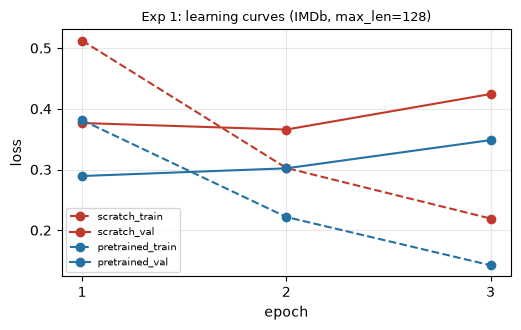

*Ảnh đã lưu: `exp1_learning_curves.png` (đọc lại từ đĩa)*

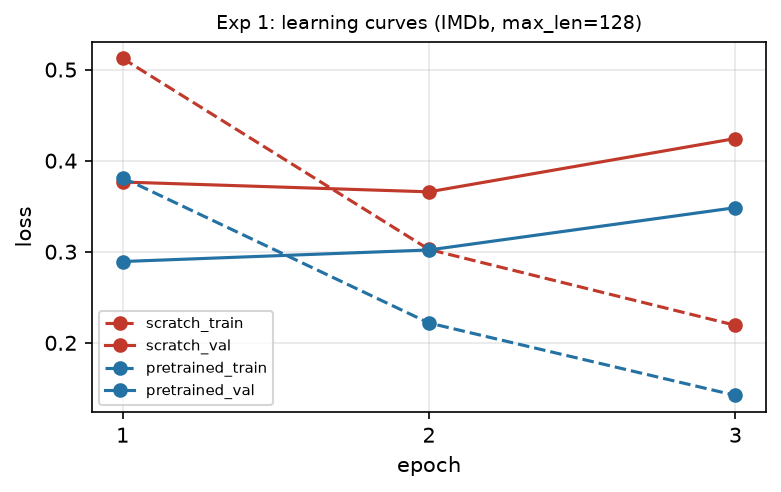

In [13]:
md_("**Sweep lr của scratch (25% train, chọn theo VAL loss):**")
display(sweep.round(4))
print("lr chon theo val loss =", best_lr)
md_("**Bảng Exp 1 (đọc từ `results.csv`)**")
show(xr("exp1_scratch") .pipe(lambda d: pd.concat([d, xr("exp1_pretrained"), xr("exp1_scratch_lab07_transformer")])), ["experiment"])
h = pd.DataFrame({"scratch_train": [e["train_loss"] for e in R[MAIN_SC]["history"]], "scratch_val": [e["val_loss"] for e in R[MAIN_SC]["history"]],
                  "pretrained_train": [e["train_loss"] for e in R[MAIN_FT]["history"]], "pretrained_val": [e["val_loss"] for e in R[MAIN_FT]["history"]]}, index=pd.Index([1, 2, 3], name="epoch"))
md_("**Loss theo epoch (learning curves):**"); display(h.round(4))
fig, ax = plt.subplots(figsize=(5.4, 3.4))
for c, st in (("scratch_train", "--"), ("scratch_val", "-"), ("pretrained_train", "--"), ("pretrained_val", "-")):
    ax.plot(h.index, h[c], st, marker="o", color="#c0392b" if "scratch" in c else "#2471a3", label=c)
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_xticks([1, 2, 3]); ax.legend(fontsize=7); ax.grid(alpha=.3); ax.set_title("Exp 1: learning curves (IMDb, max_len=128)", fontsize=9)
fig.tight_layout(); save_show(fig, "exp1_learning_curves.png")

In [14]:
hs, hp = R[MAIN_SC]["history"], R[MAIN_FT]["history"]
f_ft, f_sc, f_fz = T(MAIN_FT)["f1"], T(MAIN_SC)["f1"], T(MAIN_FZ)["f1"]
a_ft, a_sc, a_fz = T(MAIN_FT)["accuracy"], T(MAIN_SC)["accuracy"], T(MAIN_FZ)["accuracy"]
t_ft, t_sc, t_fz = R[MAIN_FT]["train_time_s"], R[MAIN_SC]["train_time_s"], R[MAIN_FZ]["train_time_s"]
ag = lambda df, pct, col="f1_mean": df.loc[df.train_pct == pct, col].item()
f10_ft, f10_sc, f100_ft, f100_sc = ag(ag_ft, 10), ag(ag_sc, 10), ag(ag_ft, 100), ag(ag_sc, 100)
sd = lambda df, pct: ag(df, pct, "f1_std")
bs_, bp_ = R[MAIN_SC]["best_epoch"], R[MAIN_FT]["best_epoch"]
md_(f"""**Trả lời mục 14 (observation → evidence → interpretation)**

1. **Representation khác nhau thế nào?** *Observation:* cùng kiến trúc, cùng {R[MAIN_FT]['params_total']:,} tham số; F1 test pretrained **{f_ft:.4f}** so với scratch **{f_sc:.4f}** (+{f_ft - f_sc:.4f}), accuracy {a_ft:.4f} so với {a_sc:.4f}. *Evidence:* train loss epoch 1: scratch {hs[0]['train_loss']:.4f} vs pretrained {hp[0]['train_loss']:.4f}; val loss epoch 1: {hs[0]['val_loss']:.4f} vs {hp[0]['val_loss']:.4f}; val loss thấp nhất ở epoch {bs_} (scratch) và epoch {bp_} (pretrained){', sau đó cả hai tăng lại (overfit trong 3 epoch)' if bs_ < 3 and bp_ < 3 else ''}. *Interpretation:* pretrained bắt đầu từ điểm mà `[CLS]` đã chứa thông tin dùng được (frozen đạt F1 {f_fz:.4f} chỉ với head), scratch phải học từ vựng/ngữ cảnh từ chỉ {R[MAIN_FT]['n_train']:,} review. Chưa phân tích trực tiếp không gian biểu diễn (không probe/visualization) nên đây là suy luận gián tiếp.
2. **Cần bao nhiêu dữ liệu?** F1 scratch ở 100% data = {f100_sc:.4f} ≈ pretrained ở 10% = {f10_ft:.4f} (std {sd(ag_sc, 100):.4f} và {sd(ag_ft, 10):.4f}) ⇒ pretrained cần xấp xỉ ít hơn ~10× dữ liệu có nhãn cho F1 tương đương *trong cấu hình này* (so hai điểm, không nội suy).
3. **Chi phí tính toán?** Cùng kiến trúc nên chi phí mỗi epoch gần như bằng nhau: {t_sc:.1f} s (scratch) vs {t_ft:.1f} s (pretrained), peak {R[MAIN_SC]['peak_mem_mb']:.0f} vs {R[MAIN_FT]['peak_mem_mb']:.0f} MB (chênh trong nhiễu ±5%). Chi phí **pretraining** (rất lớn) không nằm trong lab và không đo; lợi thế của pretrained là chất lượng/data, không phải thời gian. """
    + (f"Transformer nhỏ LAB 07 rẻ hơn nhiều ({A_PRIME['train_time_s']:.1f} s, {A_PRIME['params']:,} tham số, {A_PRIME['peak_mem_mb']:.0f} MB) nhưng F1 {A_PRIME['f1']:.4f} ≈ scratch DistilBERT ({f_sc:.4f}) ⇒ tăng số tham số một mình không giúp." if "error" not in A_PRIME else "") + f"""
4. **Khớp prediction không?** Xem mục 15. Kết quả thực: pretrained hơn scratch +{f_ft - f_sc:.4f} F1.""")

**Trả lời mục 14 (observation → evidence → interpretation)**

1. **Representation khác nhau thế nào?** *Observation:* cùng kiến trúc, cùng 66,364,418 tham số; F1 test pretrained **0.8782** so với scratch **0.8404** (+0.0379), accuracy 0.8734 so với 0.8352. *Evidence:* train loss epoch 1: scratch 0.5124 vs pretrained 0.3813; val loss epoch 1: 0.3766 vs 0.2893; val loss thấp nhất ở epoch 2 (scratch) và epoch 1 (pretrained), sau đó cả hai tăng lại (overfit trong 3 epoch). *Interpretation:* pretrained bắt đầu từ điểm mà `[CLS]` đã chứa thông tin dùng được (frozen đạt F1 0.8103 chỉ với head), scratch phải học từ vựng/ngữ cảnh từ chỉ 31,879 review. Chưa phân tích trực tiếp không gian biểu diễn (không probe/visualization) nên đây là suy luận gián tiếp.
2. **Cần bao nhiêu dữ liệu?** F1 scratch ở 100% data = 0.8398 ≈ pretrained ở 10% = 0.8386 (std 0.0018 và 0.0073) ⇒ pretrained cần xấp xỉ ít hơn ~10× dữ liệu có nhãn cho F1 tương đương *trong cấu hình này* (so hai điểm, không nội suy).
3. **Chi phí tính toán?** Cùng kiến trúc nên chi phí mỗi epoch gần như bằng nhau: 476.6 s (scratch) vs 497.1 s (pretrained), peak 1707 vs 1704 MB (chênh trong nhiễu ±5%). Chi phí **pretraining** (rất lớn) không nằm trong lab và không đo; lợi thế của pretrained là chất lượng/data, không phải thời gian. Transformer nhỏ LAB 07 rẻ hơn nhiều (50.5 s, 4,105,089 tham số, 456 MB) nhưng F1 0.8349 ≈ scratch DistilBERT (0.8404) ⇒ tăng số tham số một mình không giúp.
4. **Khớp prediction không?** Xem mục 15. Kết quả thực: pretrained hơn scratch +0.0379 F1.

## 8. Exp 2 — Frozen (feature extraction) vs Fine-tuning (mục 15)
Lr riêng: frozen = 1e-3 (chỉ head Linear 768×2), fine-tune = 2e-5 (cả encoder). Cùng split/`max_len`/epochs/batch. Encoder frozen luôn ở `eval()` (tắt dropout bên trong) và chạy dưới `no_grad`.

In [15]:
show(pd.concat([xr("exp2_frozen"), xr("exp2_finetune")]), ["experiment"])
hz, hf = R[MAIN_FZ]["history"], R[MAIN_FT]["history"]
display(pd.DataFrame({"frozen_train": [e["train_loss"] for e in hz], "frozen_val": [e["val_loss"] for e in hz], "finetune_train": [e["train_loss"] for e in hf], "finetune_val": [e["val_loss"] for e in hf]}, index=pd.Index([1, 2, 3], name="epoch")).round(4))
md_(f"""**Trả lời mục 15.**

- **Vì sao frozen vẫn classify được?** *Observation:* F1 **{f_fz:.4f}** chỉ với {R[MAIN_FZ]['params_trainable']:,} tham số trainable (đoán mò ≈ 0.5). *Evidence:* encoder pretrain đã sinh `[CLS]` mà một lớp Linear phân tách được; encoder không đổi (unit test `test_freeze_only_trains_head_and_keeps_encoder_unchanged`). *Interpretation:* thông tin liên quan sentiment (từ cảm xúc, ngữ cảnh) đã nằm trong biểu diễn pretrain và gần tuyến tính, nên chỉ cần học head. Giới hạn: không đo trực tiếp "thông tin gì" nằm trong biểu diễn.
- **Vì sao fine-tuning cải thiện?** *Observation:* +{f_ft - f_fz:.4f} F1, recall {T(MAIN_FZ)['recall']:.4f} → {T(MAIN_FT)['recall']:.4f}; thời gian {t_fz:.1f} s → {t_ft:.1f} s (×{t_ft / t_fz:.1f}), peak {R[MAIN_FZ]['peak_mem_mb']:.0f} → {R[MAIN_FT]['peak_mem_mb']:.0f} MB. *Evidence:* fine-tune cập nhật {R[MAIN_FT]['params_trainable']:,} tham số; frozen train 3 epoch, val loss còn đang giảm ({hz[0]['val_loss']:.4f} → {hz[1]['val_loss']:.4f} → {hz[2]['val_loss']:.4f}). *Interpretation:* điều chỉnh các lớp trong encoder để gom tín hiệu cảm xúc đúng chỗ `[CLS]` (DistilBERT không có NSP) và thích nghi từ vựng IMDb; một phần khoảng cách có thể do head chưa hội tụ và hyperparameter chưa tune (chưa thử nhiều epoch/mean-pooling).""")

,experiment,params_total,params_trainable,train_time_s,peak_mem_mb,accuracy,precision,recall,f1
0,exp2_frozen,66364418,1538,124.76,608.3,0.8129,0.8217,0.7992,0.8103
1,exp2_finetune,66364418,66364418,497.15,1704.0,0.8734,0.8459,0.9132,0.8782


,frozen_train,frozen_val,finetune_train,finetune_val
epoch,,,,
1,0.5034,0.4229,0.3813,0.2893
2,0.4295,0.4125,0.2218,0.3020
3,0.4201,0.4092,0.1423,0.3484


**Trả lời mục 15.**

- **Vì sao frozen vẫn classify được?** *Observation:* F1 **0.8103** chỉ với 1,538 tham số trainable (đoán mò ≈ 0.5). *Evidence:* encoder pretrain đã sinh `[CLS]` mà một lớp Linear phân tách được; encoder không đổi (unit test `test_freeze_only_trains_head_and_keeps_encoder_unchanged`). *Interpretation:* thông tin liên quan sentiment (từ cảm xúc, ngữ cảnh) đã nằm trong biểu diễn pretrain và gần tuyến tính, nên chỉ cần học head. Giới hạn: không đo trực tiếp "thông tin gì" nằm trong biểu diễn.
- **Vì sao fine-tuning cải thiện?** *Observation:* +0.0679 F1, recall 0.7992 → 0.9132; thời gian 124.8 s → 497.1 s (×4.0), peak 608 → 1704 MB. *Evidence:* fine-tune cập nhật 66,364,418 tham số; frozen train 3 epoch, val loss còn đang giảm (0.4229 → 0.4125 → 0.4092). *Interpretation:* điều chỉnh các lớp trong encoder để gom tín hiệu cảm xúc đúng chỗ `[CLS]` (DistilBERT không có NSP) và thích nghi từ vựng IMDb; một phần khoảng cách có thể do head chưa hội tụ và hyperparameter chưa tune (chưa thử nhiều epoch/mean-pooling).

## 9. Exp 3 — Data efficiency (mục 16)
`train_frac` ∈ {10, 25, 50, 100}% cho **cả** pretrained và scratch; val/test cố định; 3 seed (42/43/44 — seed đổi khởi tạo head/scratch, thứ tự batch **và** subset). Subset phân tầng theo nhãn, lồng nhau theo seed.

,model,train_pct,accuracy,accuracy_std,f1,f1_std,train_time_s,peak_mem_mb
0,pretrained,10,0.8436,0.0038,0.8386,0.0073,47.25,1706.4
1,pretrained,25,0.8603,0.0075,0.8593,0.0109,119.36,1706.5
2,pretrained,50,0.8700,0.0041,0.8736,0.0036,239.86,1706.5
3,pretrained,100,0.8803,0.0093,0.8820,0.0065,479.22,1705.7
4,scratch,10,0.7521,0.0066,0.7410,0.0168,47.30,1706.4
5,scratch,25,0.7960,0.0212,0.7847,0.0329,120.28,1706.5
6,scratch,50,0.8202,0.0077,0.8206,0.0173,236.16,1706.5
7,scratch,100,0.8348,0.0030,0.8398,0.0018,472.30,1706.5


**Khoảng cách F1 (pretrained − scratch) theo % data:**

,train_pct,F1_pretrained - F1_scratch
0,10,0.0977
1,25,0.0746
2,50,0.0530
3,100,0.0422


Pretrained: F1 100% = 0.8820, 10% = 0.8386, giam 0.0434 (4.9% tuong doi)
Scratch   : F1 100% = 0.8398, 10% = 0.7410, giam 0.0989 (11.8% tuong doi)
pretrained > scratch o MOI (muc data, seed): True


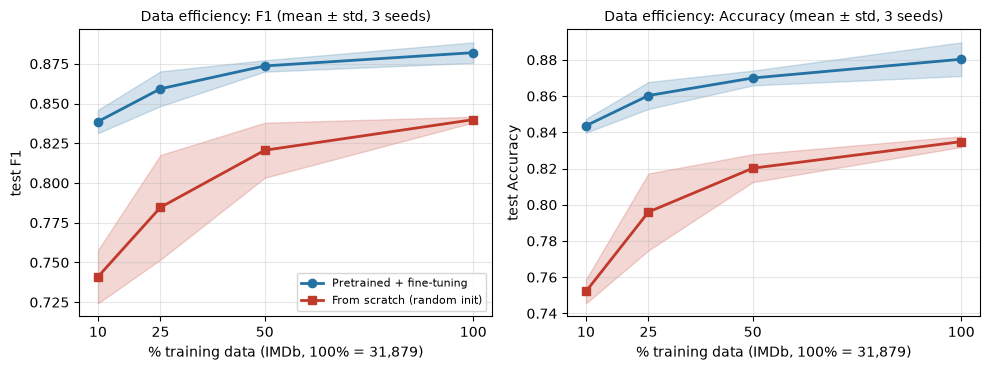

*Ảnh đã lưu: `data_efficiency.png` (đọc lại từ đĩa)*

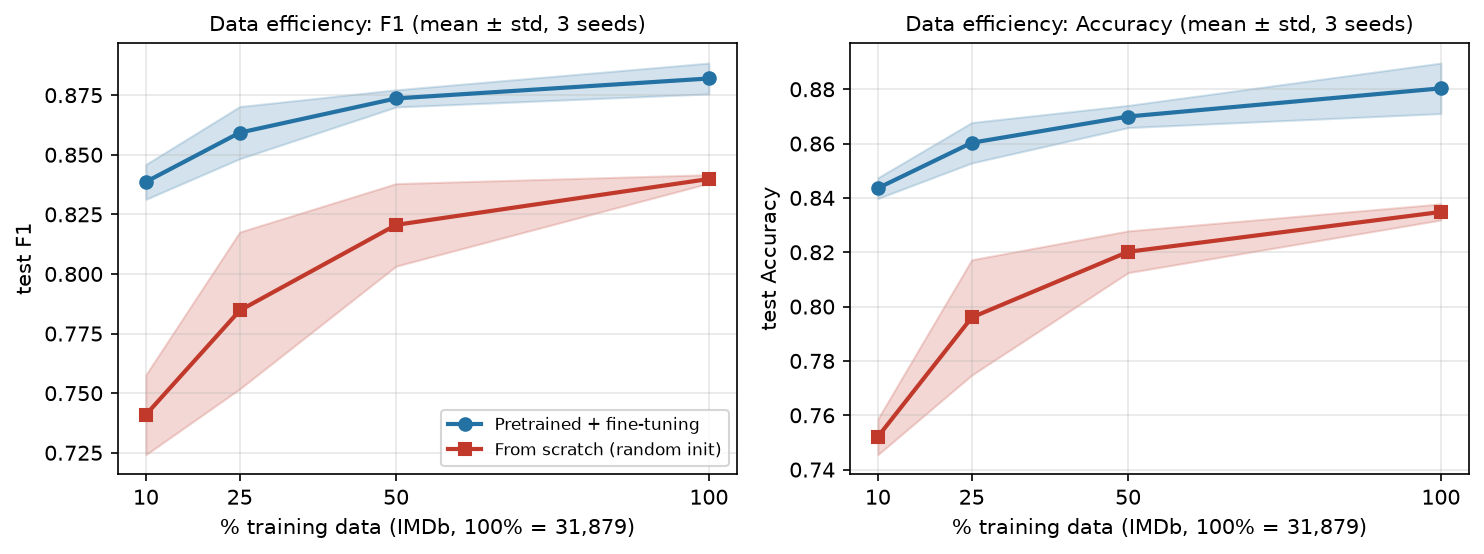

In [16]:
e3 = xr("exp3_data_efficiency_mean", ["model", "train_pct", "accuracy_std", "f1_std", "f1_per_seed"])
show(e3, ["model", "train_pct"], ["accuracy", "accuracy_std", "f1", "f1_std", "train_time_s", "peak_mem_mb"])
gap = pd.DataFrame({"train_pct": ag_ft.train_pct, "F1_pretrained - F1_scratch": (ag_ft.f1_mean - ag_sc.f1_mean).values}); md_("**Khoảng cách F1 (pretrained − scratch) theo % data:**"); display(gap.round(4))
drop_ft, drop_sc = f100_ft - f10_ft, f100_sc - f10_sc
print(f"Pretrained: F1 100% = {f100_ft:.4f}, 10% = {f10_ft:.4f}, giam {drop_ft:.4f} ({drop_ft / f100_ft * 100:.1f}% tuong doi)")
print(f"Scratch   : F1 100% = {f100_sc:.4f}, 10% = {f10_sc:.4f}, giam {drop_sc:.4f} ({drop_sc / f100_sc * 100:.1f}% tuong doi)")
# pretrained cao hon scratch o moi seed va moi muc data?
per_seed = all(R[pc.run_name("ft", frac=f, seed=s_)]["test"]["A"]["f1"] > R[pc.run_name("scratch", frac=f, seed=s_)]["test"]["A"]["f1"] for f in FR for s_ in SEEDS)
print("pretrained > scratch o MOI (muc data, seed):", per_seed)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, key, lab in ((axes[0], "f1", "F1"), (axes[1], "accuracy", "Accuracy")):
    for agg_, name, color, mk_ in ((ag_ft, "Pretrained + fine-tuning", "#2471a3", "o"), (ag_sc, "From scratch (random init)", "#c0392b", "s")):
        x, mu, sg = agg_.train_pct.values, agg_[f"{key}_mean"].values, agg_[f"{key}_std"].values
        ax.plot(x, mu, marker=mk_, color=color, label=name, lw=2); ax.fill_between(x, mu - sg, mu + sg, color=color, alpha=.2)
    ax.set_xlabel("% training data (IMDb, 100% = 31,879)"); ax.set_ylabel("test " + lab); ax.set_xticks([10, 25, 50, 100]); ax.grid(alpha=.3)
    ax.set_title(f"Data efficiency: {lab} (mean ± std, 3 seeds)", fontsize=10)
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout(); save_show(fig, "data_efficiency.png")

In [17]:
gaps = (ag_ft.f1_mean - ag_sc.f1_mean).tolist()
md_(f"""**Trả lời mục 16 — toàn bộ đường cong.** *Observation:* pretrained cao hơn ở cả 4 điểm{' và ở mọi seed' if per_seed else ''} (`data_efficiency.png`); khoảng cách F1 {gaps[0]:.4f} → {gaps[1]:.4f} → {gaps[2]:.4f} → {gaps[3]:.4f}; từ 100% xuống 10%, pretrained mất {drop_ft:.4f} F1, scratch mất {drop_sc:.4f}. Đường pretrained gần phẳng từ 25% ({ag(ag_ft, 25):.4f}) tới 100% ({f100_ft:.4f}): gấp 4 lần data chỉ +{f100_ft - ag(ag_ft, 25):.4f}; scratch còn dốc ({ag(ag_sc, 25):.4f} → {f100_sc:.4f} = +{f100_sc - ag(ag_sc, 25):.4f}) và std lớn hơn (tới {ag_sc.f1_std.max():.4f}). *Interpretation:* pretraining giúp dùng dữ liệu downstream hiệu quả hơn — tốt hơn ở *mọi* lượng data đã thử và hưởng lợi nhiều nhất khi data ít — nhưng khoảng cách thu hẹp, nên không nên ngoại suy rằng scratch không bao giờ đuổi kịp (chưa thử >100% data hay nhiều epoch hơn). *Cỡ mẫu:* 3 seed, std ≤ {max(ag_ft.f1_std.max(), ag_sc.f1_std.max()):.3f}; khoảng cách ≥ {min(gaps):.3f} vượt xa nhiễu, nhưng chênh giữa các điểm gần nhau của riêng pretrained (50% so với 100%: {ag(ag_ft, 50):.4f} vs {f100_ft:.4f}, std {sd(ag_ft, 50):.4f}/{sd(ag_ft, 100):.4f}) thì không chắc chắn.""")

**Trả lời mục 16 — toàn bộ đường cong.** *Observation:* pretrained cao hơn ở cả 4 điểm và ở mọi seed (`data_efficiency.png`); khoảng cách F1 0.0977 → 0.0746 → 0.0530 → 0.0422; từ 100% xuống 10%, pretrained mất 0.0434 F1, scratch mất 0.0989. Đường pretrained gần phẳng từ 25% (0.8593) tới 100% (0.8820): gấp 4 lần data chỉ +0.0227; scratch còn dốc (0.7847 → 0.8398 = +0.0552) và std lớn hơn (tới 0.0329). *Interpretation:* pretraining giúp dùng dữ liệu downstream hiệu quả hơn — tốt hơn ở *mọi* lượng data đã thử và hưởng lợi nhiều nhất khi data ít — nhưng khoảng cách thu hẹp, nên không nên ngoại suy rằng scratch không bao giờ đuổi kịp (chưa thử >100% data hay nhiều epoch hơn). *Cỡ mẫu:* 3 seed, std ≤ 0.033; khoảng cách ≥ 0.042 vượt xa nhiễu, nhưng chênh giữa các điểm gần nhau của riêng pretrained (50% so với 100%: 0.8736 vs 0.8820, std 0.0036/0.0065) thì không chắc chắn.

## 10. Exp 4 — Maximum sequence length (mục 17)
$T \in \{64, 128, 256\}$, pretrained + fine-tune, mọi thứ khác giữ nguyên. Memory = `torch.cuda.max_memory_allocated()` (train + val). Lý thuyết: self-attention $O(T^2)$ về thời gian và bộ nhớ scores; FFN/projection $O(T)$.

In [18]:
e4 = xr("exp4_max_len", ["max_len", "test_truncated_pct", "best_epoch"])
show(e4, ["max_len"], ["accuracy", "f1", "train_time_s", "peak_mem_mb"])
display(e4[["max_len", "test_truncated_pct", "best_epoch"]].round(2))
b4 = e4.set_index("max_len")
for a_, b_ in ((64, 128), (128, 256)):
    print(f"T {a_}->{b_}: F1 {b4.loc[b_, 'f1'] - b4.loc[a_, 'f1']:+.4f} | time x{b4.loc[b_, 'train_time_s'] / b4.loc[a_, 'train_time_s']:.2f} | peak mem x{b4.loc[b_, 'peak_mem_mb'] / b4.loc[a_, 'peak_mem_mb']:.2f}  (T tang x2)")

,max_len,accuracy,f1,train_time_s,peak_mem_mb
0,64,0.8368,0.8413,326.93,1312.9
1,128,0.8734,0.8782,497.15,1704.0
2,256,0.9117,0.9136,862.97,2532.2


,max_len,test_truncated_pct,best_epoch
0,64,98.02,2
1,128,88.01,1
2,256,40.75,1


T 64->128: F1 +0.0370 | time x1.52 | peak mem x1.30  (T tang x2)
T 128->256: F1 +0.0353 | time x1.74 | peak mem x1.49  (T tang x2)


In [19]:
t_r = lambda a_, b_: b4.loc[b_, "train_time_s"] / b4.loc[a_, "train_time_s"]; mem_r = lambda a_, b_: b4.loc[b_, "peak_mem_mb"] / b4.loc[a_, "peak_mem_mb"]
md_(f"""**Trả lời mục 17.** *Observation:* T 64 → 128 → 256 tăng F1 {b4.loc[64, 'f1']:.4f} → {b4.loc[128, 'f1']:.4f} → {b4.loc[256, 'f1']:.4f}; thời gian ×{t_r(64, 128):.2f}, ×{t_r(128, 256):.2f} mỗi lần gấp đôi T; peak memory ×{mem_r(64, 128):.2f}, ×{mem_r(128, 256):.2f}. *Evidence:* tỷ lệ test bị cắt {b4.loc[64, 'test_truncated_pct']:.1f}% → {b4.loc[128, 'test_truncated_pct']:.1f}% → {b4.loc[256, 'test_truncated_pct']:.1f}%; accuracy theo độ dài review giảm ở review dài (mục 14). *Interpretation:* ở dữ liệu này **tăng T có ích** vì phần bị cắt chứa lời kết luận (mẫu #3, #6 ở mục 14 đảo đúng nhãn khi thấy phần sau), nhưng không phải luôn luôn: lợi ích chỉ có khi phần bị cắt còn chứa tín hiệu, còn chi phí attention tăng $O(T^2)$. Thời gian đo tăng *dưới* bậc 2 vì FFN/projection là $O(T)$, padding động (không phải review nào cũng đầy `T`) và chi phí cố định; peak memory đo gồm cả batch validation 128 mẫu nên không phải memory attention thuần (không suy ra "$O(T^2)$" từ ba điểm này). Chưa thử T=512, nên chưa biết điểm bão hoà (Q6).""")

**Trả lời mục 17.** *Observation:* T 64 → 128 → 256 tăng F1 0.8413 → 0.8782 → 0.9136; thời gian ×1.52, ×1.74 mỗi lần gấp đôi T; peak memory ×1.30, ×1.49. *Evidence:* tỷ lệ test bị cắt 98.0% → 88.0% → 40.8%; accuracy theo độ dài review giảm ở review dài (mục 14). *Interpretation:* ở dữ liệu này **tăng T có ích** vì phần bị cắt chứa lời kết luận (mẫu #3, #6 ở mục 14 đảo đúng nhãn khi thấy phần sau), nhưng không phải luôn luôn: lợi ích chỉ có khi phần bị cắt còn chứa tín hiệu, còn chi phí attention tăng $O(T^2)$. Thời gian đo tăng *dưới* bậc 2 vì FFN/projection là $O(T)$, padding động (không phải review nào cũng đầy `T`) và chi phí cố định; peak memory đo gồm cả batch validation 128 mẫu nên không phải memory attention thuần (không suy ra "$O(T^2)$" từ ba điểm này). Chưa thử T=512, nên chưa biết điểm bão hoà (Q6).

## 11. Exp 5 — Domain shift (mục 18)
A = IMDb (phim), B = Yelp (nhà hàng/dịch vụ), cùng task nhị phân. Test A và test B đều 10,000 mẫu cố định; train A và train B đều 31,879 mẫu. Tham chiếu: B→B.

In [20]:
e5 = xr("exp5_domain_shift", ["model", "setting"])
show(e5, ["model", "setting"], ["accuracy", "precision", "recall", "f1"])
e5i = e5.set_index(["model", "setting"])
print("Ma tran nham lan A->B (pretrained) [[TN, FP], [FN, TP]]:", R[MAIN_FT]["test"]["B"]["confusion_matrix"])

,model,setting,accuracy,precision,recall,f1
0,pretrained,A->A,0.8734,0.8459,0.9132,0.8782
1,pretrained,A->B,0.8516,0.7968,0.9440,0.8642
2,pretrained,B->B (reference),0.9207,0.9068,0.9378,0.9220
3,pretrained,B->A (reverse),0.8221,0.8293,0.8112,0.8201
4,scratch,A->A,0.8352,0.8148,0.8676,0.8404
5,scratch,A->B,0.7625,0.7266,0.8416,0.7799


Ma tran nham lan A->B (pretrained) [[TN, FP], [FN, TP]]: [[3796, 1204], [280, 4720]]


In [21]:
ii, oo = e5i.loc[("pretrained", "A->A")], e5i.loc[("pretrained", "A->B")]; bb_ = e5i.loc[("pretrained", "B->B (reference)")]; ba_ = e5i.loc[("pretrained", "B->A (reverse)")]
si, so = e5i.loc[("scratch", "A->A")], e5i.loc[("scratch", "A->B")]
(tn_b, fp_b), (fn_b, tp_b) = R[MAIN_FT]["test"]["B"]["confusion_matrix"]
md_(f"""**Trả lời mục 18.** *Observation:* pretrained fine-tune trên IMDb → Yelp: accuracy {ii.accuracy:.4f} → {oo.accuracy:.4f} (−{ii.accuracy - oo.accuracy:.4f}), thiếu {bb_.accuracy - oo.accuracy:.4f} so với B→B ({bb_.accuracy:.4f}); precision {ii.precision:.4f} → {oo.precision:.4f}, recall {ii.recall:.4f} → {oo.recall:.4f} (FP {fp_b:,} ≫ FN {fn_b:,}); chiều ngược B→A: {ba_.accuracy:.4f}. Scratch tụt nhiều hơn ({si.accuracy:.4f} → {so.accuracy:.4f}, −{si.accuracy - so.accuracy:.4f}). *Interpretation:* pretrained **không** "hiểu mọi domain": vẫn kém model huấn luyện trong domain đích {(bb_.accuracy - oo.accuracy) * 100:.1f} điểm accuracy và lệch về positive; chênh nhỏ hơn scratch cho thấy pretraining giảm một phần (không loại bỏ) domain shift. Vì Yelp "dễ" hơn IMDb ở cùng `max_len` (B→B {bb_.accuracy:.4f}), thước đo công bằng hơn là A→B so với B→B chứ không phải A→A. Nguyên nhân cụ thể (từ vựng, độ dài, định nghĩa nhãn, forgetting) chưa được tách — chỉ là giả thuyết (Q5).""")

**Trả lời mục 18.** *Observation:* pretrained fine-tune trên IMDb → Yelp: accuracy 0.8734 → 0.8516 (−0.0218), thiếu 0.0691 so với B→B (0.9207); precision 0.8459 → 0.7968, recall 0.9132 → 0.9440 (FP 1,204 ≫ FN 280); chiều ngược B→A: 0.8221. Scratch tụt nhiều hơn (0.8352 → 0.7625, −0.0727). *Interpretation:* pretrained **không** "hiểu mọi domain": vẫn kém model huấn luyện trong domain đích 6.9 điểm accuracy và lệch về positive; chênh nhỏ hơn scratch cho thấy pretraining giảm một phần (không loại bỏ) domain shift. Vì Yelp "dễ" hơn IMDb ở cùng `max_len` (B→B 0.9207), thước đo công bằng hơn là A→B so với B→B chứ không phải A→A. Nguyên nhân cụ thể (từ vựng, độ dài, định nghĩa nhãn, forgetting) chưa được tách — chỉ là giả thuyết (Q5).

## 12. Application — Sentiment classification (mục 19)
Model: **fine-tuned có val F1 cao nhất** trong 3 cấu hình `max_len` (chọn bằng validation, không nhìn test). Metrics: Accuracy, Precision, Recall, F1 (lớp positive = 1) + confusion matrix.

val F1 cac ung vien: {'ft_A_len64_frac1.0_s42': 0.8434, 'ft_A_len128_frac1.0_s42': 0.8766, 'ft_A_len256_frac1.0_s42': 0.9171} => BEST = ft_A_len256_frac1.0_s42


,experiment,params_total,params_trainable,train_time_s,peak_mem_mb,accuracy,precision,recall,f1
0,application_best_model,66364418,66364418,862.97,2532.2,0.9117,0.8944,0.9336,0.9136


              precision    recall  f1-score   support

    negative     0.9306    0.8898    0.9097      5000
    positive     0.8944    0.9336    0.9136      5000

    accuracy                         0.9117     10000
   macro avg     0.9125    0.9117    0.9117     10000
weighted avg     0.9125    0.9117    0.9117     10000

TN=4449 FP=551 FN=332 TP=4668  | FP rate=0.1102  FN rate=0.0664


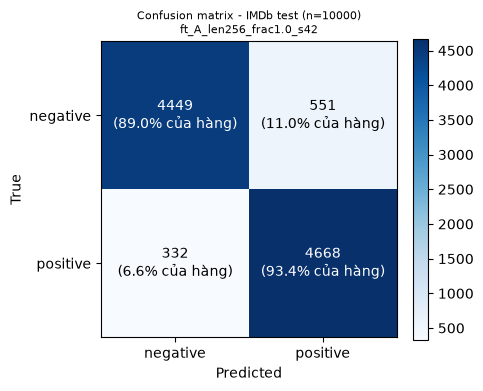

*Ảnh đã lưu: `confusion_matrix.png` (đọc lại từ đĩa)*

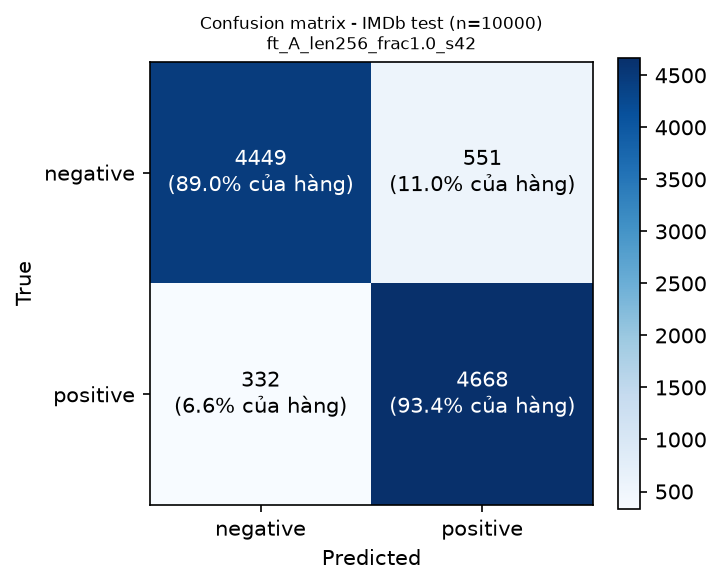

In [22]:
from sklearn.metrics import classification_report
print("val F1 cac ung vien:", {k_: round(v, 4) for k_, v in val_f1.items()}, "=> BEST =", BEST)
show(xr("application_best_model"), ["experiment"])
print(classification_report(y, pred, target_names=pc.LABEL_NAMES, digits=4))
print(f"TN={tn} FP={fp} FN={fn} TP={tp}  | FP rate={fp / (fp + tn):.4f}  FN rate={fn / (fn + tp):.4f}")
fig, ax = plt.subplots(figsize=(4.8, 4.2)); im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}% của hàng)", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=10)
ax.set_xticks([0, 1], pc.LABEL_NAMES); ax.set_yticks([0, 1], pc.LABEL_NAMES); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix - IMDb test (n={len(y)})\n{BEST}", fontsize=8); fig.colorbar(im, fraction=.046); fig.tight_layout(); save_show(fig, "confusion_matrix.png")

In [23]:
md_(f"""**Nhận xét.** Model `{BEST}` (`max_len`={R[BEST]['cfg']['max_len']}, val F1 {val_f1[BEST]:.4f}): accuracy **{m['accuracy']:.4f}**, precision {m['precision']:.4f}, recall {m['recall']:.4f}, F1 **{m['f1']:.4f}**. Tổng lỗi {fp + fn} = FP {fp} ({fp / (fp + tn) * 100:.1f}% review negative) + FN {fn} ({fn / (fn + tp) * 100:.1f}% review positive) ⇒ model thiên về dự đoán *positive* (recall {m['recall']:.4f} > precision {m['precision']:.4f}).""")

**Nhận xét.** Model `ft_A_len256_frac1.0_s42` (`max_len`=256, val F1 0.9171): accuracy **0.9117**, precision 0.8944, recall 0.9336, F1 **0.9136**. Tổng lỗi 883 = FP 551 (11.0% review negative) + FN 332 (6.6% review positive) ⇒ model thiên về dự đoán *positive* (recall 0.9336 > precision 0.8944).

## 13. Confidence analysis (mục 21)
`confidence = softmax(logits).max()`. Ngưỡng: **High ≥ 0.9**, **Medium 0.7–0.9**, **Low < 0.7**.

,group,n,pct_of_test,accuracy,n_wrong,mean_confidence
0,High (>=0.9),7877,78.77,0.9689,245,0.9812
1,Medium (0.7-0.9),1346,13.46,0.7600,323,0.8177
2,Low (<0.7),777,7.77,0.5946,315,0.6078


Tong loi = 883; loi o nhom High = 245 (27.7% tong loi); loi o nhom Low = 315
Confidence TB khi dung = 0.9454, khi sai = 0.7732 | sai voi conf>=0.95: 143, >=0.99: 28
ECE (10 bin) = 0.0206


,lo,hi,n,mean_conf,accuracy
0,0.50,0.55,175,0.5279,0.5714
1,0.55,0.60,172,0.5757,0.5930
2,0.60,0.65,187,0.6249,0.5401
3,0.65,0.70,243,0.6748,0.6543
4,0.70,0.75,241,0.7258,0.6515
5,0.75,0.80,250,0.7763,0.7040
6,0.80,0.85,357,0.8254,0.7759
7,0.85,0.90,498,0.8775,0.8293
8,0.90,0.95,878,0.9284,0.8838
9,0.95,1.00,6999,0.9878,0.9796


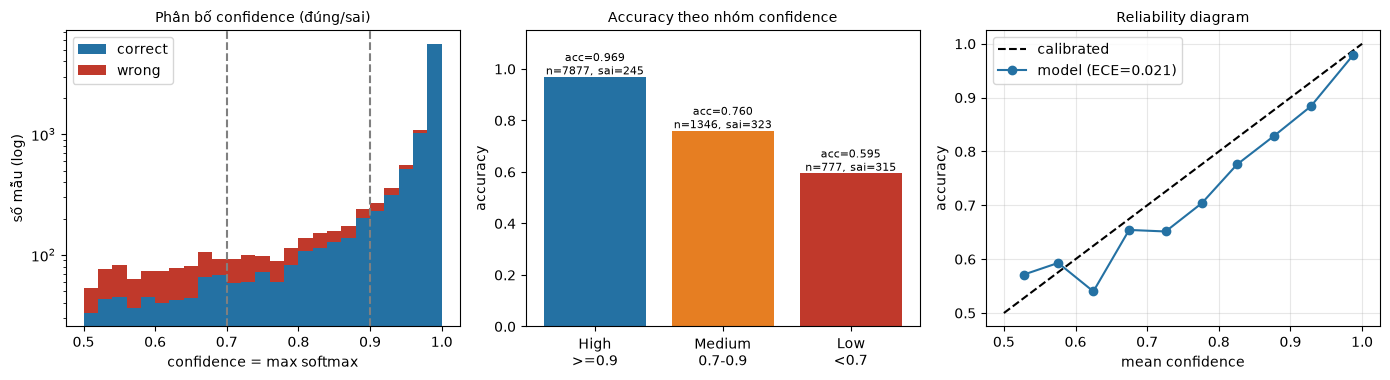

*Ảnh đã lưu: `confidence_analysis.png` (đọc lại từ đĩa)*

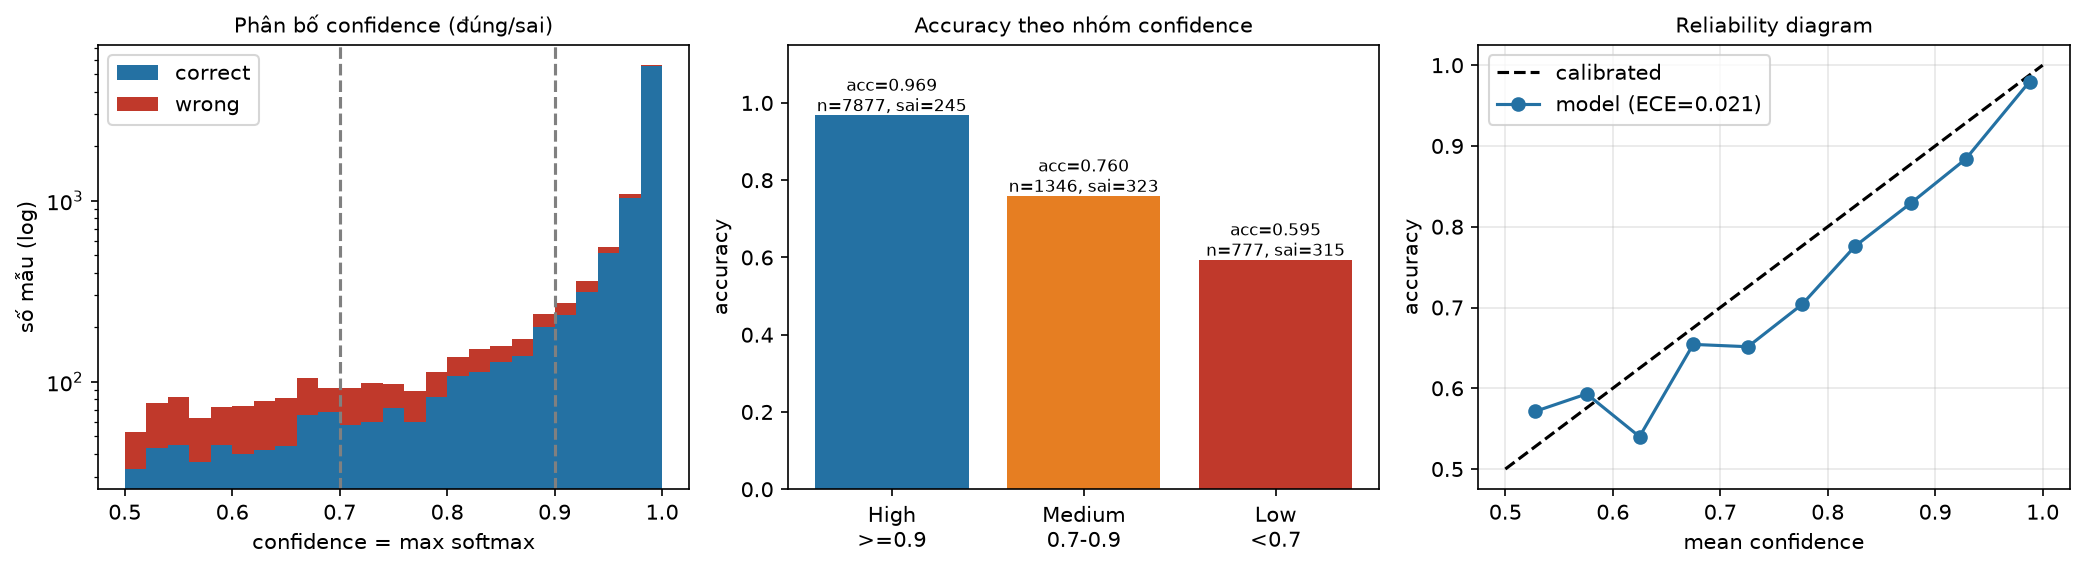

In [24]:
display(conf_tab.round(4))
hi_wrong = int(((conf >= 0.9) & wrong).sum()); lo_wrong = int(((conf < 0.7) & wrong).sum())
print(f"Tong loi = {int(wrong.sum())}; loi o nhom High = {hi_wrong} ({hi_wrong / wrong.sum() * 100:.1f}% tong loi); loi o nhom Low = {lo_wrong}")
print(f"Confidence TB khi dung = {conf[correct].mean():.4f}, khi sai = {conf[wrong].mean():.4f} | sai voi conf>=0.95: {int(((conf >= 0.95) & wrong).sum())}, >=0.99: {int(((conf >= 0.99) & wrong).sum())}")
print(f"ECE (10 bin) = {ece:.4f}")
display(pd.DataFrame(rel, columns=["lo", "hi", "n", "mean_conf", "accuracy"]).round(4))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9)); bn = np.linspace(0.5, 1.0, 26)
ax[0].hist([conf[correct], conf[wrong]], bins=bn, stacked=True, color=["#2471a3", "#c0392b"], label=["correct", "wrong"])
ax[0].set_yscale("log"); ax[0].axvline(0.7, ls="--", c="gray"); ax[0].axvline(0.9, ls="--", c="gray")
ax[0].set_xlabel("confidence = max softmax"); ax[0].set_ylabel("số mẫu (log)"); ax[0].set_title("Phân bố confidence (đúng/sai)", fontsize=10); ax[0].legend()
ax[1].bar(range(3), conf_tab.accuracy, color=["#2471a3", "#e67e22", "#c0392b"])
for i, r in conf_tab.iterrows(): ax[1].text(i, r.accuracy + 0.01, f"acc={r.accuracy:.3f}\nn={r.n}, sai={r.n_wrong}", ha="center", fontsize=8)
ax[1].set_xticks(range(3), ["High\n>=0.9", "Medium\n0.7-0.9", "Low\n<0.7"]); ax[1].set_ylim(0, 1.15); ax[1].set_ylabel("accuracy"); ax[1].set_title("Accuracy theo nhóm confidence", fontsize=10)
rl = np.array(rel); ax[2].plot([0.5, 1], [0.5, 1], "k--", label="calibrated"); ax[2].plot(rl[:, 3], rl[:, 4], "o-", color="#2471a3", label=f"model (ECE={ece:.3f})")
ax[2].set_xlabel("mean confidence"); ax[2].set_ylabel("accuracy"); ax[2].set_title("Reliability diagram", fontsize=10); ax[2].legend(); ax[2].grid(alpha=.3)
fig.tight_layout(); save_show(fig, "confidence_analysis.png")

In [25]:
cH, cM, cL = conf_tab.iloc[0], conf_tab.iloc[1], conf_tab.iloc[2]
md_(f"""**Observation:** accuracy tăng đơn điệu theo nhóm ({cL.accuracy:.3f} → {cM.accuracy:.3f} → {cH.accuracy:.3f}); confidence TB khi đúng {conf[correct].mean():.4f}, khi sai {conf[wrong].mean():.4f}; ECE {ece:.4f}.
**Evidence cho "confidence ≠ correctness":** nhóm High (≥0.9, {cH.pct_of_test:.2f}% test) vẫn chứa **{hi_wrong} lỗi = {hi_wrong / wrong.sum() * 100:.1f}% tổng số lỗi ({int(wrong.sum())})**; {int(((conf >= 0.95) & wrong).sum())} lỗi có confidence ≥ 0.95 và {int(((conf >= 0.99) & wrong).sum())} lỗi ≥ 0.99. Chỉ {lo_wrong}/{int(wrong.sum())} = {lo_wrong / wrong.sum() * 100:.1f}% lỗi nằm ở nhóm Low.
**Interpretation:** confidence là tín hiệu *có ích* (tỷ lệ sai nhóm Low {(1 - cL.accuracy) * 100:.1f}% vs nhóm High {(1 - cH.accuracy) * 100:.1f}%, gấp ~{(1 - cL.accuracy) / (1 - cH.accuracy):.0f} lần) và tương đối được hiệu chỉnh trên tập này, nhưng **không đảm bảo** đúng: hơn một phần tư lỗi vẫn "tự tin". Nếu *nhãn* mâu thuẫn với văn bản hoặc cảm xúc thực dụng khác từ vựng (mục 14, #7 và #8), model có thể rất tự tin ở đáp án mà nhãn xem là sai. Kết luận chỉ áp dụng cho domain A; chưa đo calibration ở domain B.""")

**Observation:** accuracy tăng đơn điệu theo nhóm (0.595 → 0.760 → 0.969); confidence TB khi đúng 0.9454, khi sai 0.7732; ECE 0.0206.
**Evidence cho "confidence ≠ correctness":** nhóm High (≥0.9, 78.77% test) vẫn chứa **245 lỗi = 27.7% tổng số lỗi (883)**; 143 lỗi có confidence ≥ 0.95 và 28 lỗi ≥ 0.99. Chỉ 315/883 = 35.7% lỗi nằm ở nhóm Low.
**Interpretation:** confidence là tín hiệu *có ích* (tỷ lệ sai nhóm Low 40.5% vs nhóm High 3.1%, gấp ~13 lần) và tương đối được hiệu chỉnh trên tập này, nhưng **không đảm bảo** đúng: hơn một phần tư lỗi vẫn "tự tin". Nếu *nhãn* mâu thuẫn với văn bản hoặc cảm xúc thực dụng khác từ vựng (mục 14, #7 và #8), model có thể rất tự tin ở đáp án mà nhãn xem là sai. Kết luận chỉ áp dụng cho domain A; chưa đo calibration ở domain B.

## 14. Error analysis (mục 20)
Chọn mẫu **có quy tắc, tái lập được** (seed 42), không cherry-pick: 3 FP và 3 FN ngẫu nhiên trong các lỗi; 2 mẫu "tự tin nhưng sai" = 2 lỗi có confidence cao nhất (1 FP, 1 FN) ngoài các mẫu đã chọn.
Mỗi mẫu được **kiểm tra giả thuyết bằng can thiệp**: (i) số token, có bị cắt ở `max_len` không; (ii) dự đoán lại với `max_len=512` (giới hạn vị trí; review > 512 token vẫn bị cắt); (iii) dự đoán chỉ trên **250 token cuối**; (iv) đếm từ phủ định/đối lập. Giả thuyết trong bảng **chưa** được kiểm chứng ngoài các phép thử ghi rõ.

In [26]:
test_df = A["test"].reset_index(drop=True).copy()
test_df["pred"], test_df["conf"], test_df["p_pos"] = pred, conf, probs[:, 1]
best_len = R[BEST]["cfg"]["max_len"]
tok_len = np.array([len(x) for x in tok(test_df["text"].tolist(), truncation=False)["input_ids"]])
test_df["n_tokens"] = tok_len; test_df["truncated"] = tok_len > best_len
lb = pd.cut(tok_len, [0, 64, 128, 256, 512, 10**6], labels=["<=64", "65-128", "129-256", "257-512", ">512"])
by_len = test_df.assign(len_bin=lb, ok=correct).groupby("len_bin", observed=True).agg(n=("ok", "size"), accuracy=("ok", "mean"))
md_(f"**Accuracy theo số token (best model, max_len={best_len}):**"); display(by_len.round(4))
tr_ = test_df.truncated.values
print(f"Truncated: {int(tr_.sum())} mau, acc = {correct[tr_].mean():.4f} | khong truncated: {int((~tr_).sum())} mau, acc = {correct[~tr_].mean():.4f}")

rng = np.random.RandomState(42)
fp_idx = np.where((pred == 1) & (y == 0))[0]; fn_idx = np.where((pred == 0) & (y == 1))[0]
sel_fp = sorted(rng.choice(fp_idx, 3, replace=False).tolist()); sel_fn = sorted(rng.choice(fn_idx, 3, replace=False).tolist()); taken = set(sel_fp + sel_fn)
top_fp = [i for i in fp_idx[np.argsort(-conf[fp_idx])] if i not in taken][0]; top_fn = [i for i in fn_idx[np.argsort(-conf[fn_idx])] if i not in taken][0]
groups = {"FP": sel_fp, "FN": sel_fn, "HIGH-CONF-WRONG": [int(top_fp), int(top_fn)]}
print("FP/FN tong so:", len(fp_idx), len(fn_idx), "| mau duoc chon:", groups)

NEG = ("not", "n't", "no ", "never", "nothing", "hardly", "without", "neither"); CONTR = ("but ", "however", "although", "though", "despite", "yet ", "unfortunately", "except")
try:
    model, _, _ = pc.load_model(BEST); HAVE_MODEL = True
except Exception as e:  # khong co model.pt (gitignore) -> dung bang chung da luu
    HAVE_MODEL = False; print("Khong nap duoc model.pt (", type(e).__name__, ") -> dung error_analysis_evidence.json da luu")
if HAVE_MODEL:
    probe = lambda text, ml: pc.predict_texts(model, tok, [text], max_len=ml)[0]
    evid = []
    for g, idxs in groups.items():
        for i in idxs:
            text = test_df.text.iloc[i]; ids_ = tok(text, truncation=False, add_special_tokens=False)["input_ids"]; low = text.lower()
            p_full, p_tail = probe(text, 512), probe(tok.decode(ids_[-250:]), 512)
            cut = tok.decode(tok(text, truncation=True, max_length=best_len, add_special_tokens=False)["input_ids"]) if test_df.truncated.iloc[i] else None
            evid.append({"group": g, "test_idx": int(i), "sample_id": test_df.sample_id.iloc[i], "true": pc.LABEL_NAMES[y[i]], "pred": pc.LABEL_NAMES[pred[i]], "confidence": float(conf[i]),
                         "p_pos_at_%d" % best_len: float(probs[i, 1]), "n_tokens": int(tok_len[i]), "truncated": bool(test_df.truncated.iloc[i]), "p_pos_max_len_512": float(p_full[1]),
                         "p_pos_last_250_tokens": float(p_tail[1]), "negation_hits": sum(low.count(w_) for w_ in NEG), "contrast_hits": sum(low.count(w_) for w_ in CONTR), "text": text, "text_visible_to_model": cut})
    json.dump({"best_model": BEST, "max_len": best_len, "examples": evid, "accuracy_by_length": by_len.reset_index().astype({"len_bin": str}).to_dict("records")},
              open("error_analysis_evidence.json", "w", encoding="utf-8"), indent=1, ensure_ascii=False)
    del model; torch.cuda.empty_cache()
else:
    evid = json.load(open("error_analysis_evidence.json", encoding="utf-8"))["examples"]
EV = {e["test_idx"]: e for e in evid}
assert list(EV) == [1174, 2252, 9874, 1653, 2275, 9739, 3185, 7961], "mau loi khong khop phan tich"
for e in evid:
    print(f"\n=== [{e['group']}] idx={e['test_idx']} true={e['true']} pred={e['pred']} conf={e['confidence']:.4f} | tokens={e['n_tokens']} truncated={e['truncated']} | "
          f"P(pos): @{best_len}={e['p_pos_at_%d' % best_len]:.3f}, @512={e['p_pos_max_len_512']:.3f}, last250={e['p_pos_last_250_tokens']:.3f} | neg={e['negation_hits']} contrast={e['contrast_hits']}")
    print(e["text"][:600] + (" ..." if len(e["text"]) > 600 else ""))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (701 > 512). Running this sequence through the model will result in indexing errors


**Accuracy theo số token (best model, max_len=256):**

,n,accuracy
len_bin,,
<=64,215,0.9023
65-128,1000,0.9300
129-256,4742,0.9298
257-512,2737,0.9014
>512,1306,0.8553


Truncated: 4043 mau, acc = 0.8865 | khong truncated: 5957 mau, acc = 0.9288
FP/FN tong so: 551 332 | mau duoc chon: {'FP': [1174, 2252, 9874], 'FN': [1653, 2275, 9739], 'HIGH-CONF-WRONG': [3185, 7961]}



=== [FP] idx=1174 true=negative pred=positive conf=0.9447 | tokens=850 truncated=True | P(pos): @256=0.945, @512=0.955, last250=0.592 | neg=5 contrast=4
This was the next to last film appearance by Jill Ireland, who died of cancer in 1990 after four decades as a well-known actress and producer. Ireland made quite a few waves in the press when she dropped her then-husband David McCallum in 1967, beginning her long relationship with Charles Bronson. It is a great irony that Bronson, probably the all-time leader in number of deaths rendered on-screen, had one of the most enduring marriages in film history. 'Assassination' seems to be a movie that was tucked into Cannon's production schedule for the sake of Bronson and Ireland. Ireland was already ...

=== [FP] idx=2252 true=negative pred=positive conf=0.8534 | tokens=152 truncated=False | P(pos): @256=0.853, @512=0.854, last250=0.854 | neg=3 contrast=2
There's not really that much wrong with Crash of the Moons. Basically it's a few episo

In [27]:
def P(i, k_): return EV[i][k_]
p256 = f"p_pos_at_{best_len}"
HYP = {
 1174: ("long-range dependency + ambiguous sentiment", lambda: f"Review {P(1174, 'n_tokens')} token, model chỉ thấy {best_len} token đầu (tiểu sử + hoài niệm, từ tích cực); lời chê và điểm 2/4 nằm cuối. Thử: chỉ 250 token cuối → P(pos) {P(1174, p256):.3f} → **{P(1174, 'p_pos_last_250_tokens'):.3f}** (vẫn >0.5); @512 → {P(1174, 'p_pos_max_len_512'):.3f} ⇒ truncation làm mất tín hiệu nhưng không đủ để đảo nhãn: review vốn lưng chừng."),
 2252: ("ambiguous sentiment / label ambiguity", lambda: f"Không bị cắt; P(pos) gần như không đổi khi đổi `max_len`/lấy đuôi ({P(2252, p256):.3f}/{P(2252, 'p_pos_max_len_512'):.3f}/{P(2252, 'p_pos_last_250_tokens'):.3f}) ⇒ không phải lỗi độ dài. Phủ định kép (\"not really that much wrong\", \"not great, but not bad\"; {P(2252, 'negation_hits')} hit) + tự chấm 6/10: nội dung trung tính-nhẹ-dương, mâu thuẫn nhãn negative."),
 9874: ("long-range dependency (truncation)", lambda: f"{best_len} token đầu chỉ là tóm tắt cốt truyện trung tính; toàn bộ lời đánh giá (\"squandered\", \"OK time waster\") sau token {best_len}. Thử: P(pos) **{P(9874, p256):.3f} → {P(9874, 'p_pos_max_len_512'):.3f}** (@512), {P(9874, 'p_pos_last_250_tokens'):.3f} (đuôi) ⇒ bằng chứng can thiệp mạnh: nguyên nhân là truncation."),
 1653: ("sarcasm / \"so bad it's good\" + negation", lambda: f"Không bị cắt; P(pos) = {P(1653, p256):.3f} ở mọi `max_len` ⇒ không phải độ dài. Câu đầu phủ định + từ tiêu cực (\"no denying… bad movie… isn't great\", {P(1653, 'negation_hits')} hit); tín hiệu tích cực (\"cannot wait\", \"tops my list\") chỉ hiểu qua nghĩa thực dụng. Giả thuyết: model dựa vào từ cảm xúc bề mặt (chưa thử đảo thứ tự câu)."),
 2275: ("ambiguous sentiment (review hỗn hợp)", lambda: f"Conf thấp ({P(2275, 'confidence'):.3f}). Liệt kê nhiều điểm phi thực tế ({P(2275, 'negation_hits')} hit phủ định) rồi kết bằng \"pretty decent\", \"7/10\". Thử: P(pos) {P(2275, p256):.3f} → {P(2275, 'p_pos_max_len_512'):.3f} (@512), {P(2275, 'p_pos_last_250_tokens'):.3f} (đuôi): đều <0.5 ⇒ truncation chỉ ảnh hưởng nhẹ; nguyên nhân chính là nội dung hỗn hợp."),
 9739: ("long-range dependency (truncation) + domain-specific expression", lambda: f"{best_len} token đầu mô tả chương trình châm biếm bằng từ nghe tiêu cực (\"lampooning\", \"inane questions\"); lời khen (\"brilliant satire\", \"Two thumbs up!\") sau token {best_len}. Thử: P(pos) **{P(9739, p256):.3f} → {P(9739, 'p_pos_max_len_512'):.3f}** (@512, đúng nhãn), {P(9739, 'p_pos_last_250_tokens'):.3f} (đuôi) ⇒ truncation + từ vựng châm biếm."),
 3185: ("label ambiguity (nghi nhãn nhiễu)", lambda: f"Không bị cắt, {P(3185, 'negation_hits')} hit phủ định; P(pos) = {P(3185, p256):.3f} ở mọi `max_len`. Văn bản toàn từ khen (\"best\", \"great\", \"masterpiece\") ⇒ nhiều khả năng **nhãn không khớp văn bản** hơn là model sai. Không thể chứng minh nếu không có annotator thứ hai."),
 7961: ("sarcasm / \"so bad it's good\"", lambda: f"{best_len} token đầu đã đầy từ chê (\"awful\", \"worst\"; {P(7961, 'negation_hits')} hit phủ định), đuôi cũng vậy. Thử: P(pos) {P(7961, p256):.3f}/{P(7961, 'p_pos_max_len_512'):.3f}/{P(7961, 'p_pos_last_250_tokens'):.3f} ⇒ **không** phải truncation. Người viết chê kỹ thuật nhưng thưởng thức phim (cult): cảm xúc thực dụng khác cực tính từ vựng; có thể nhãn dựa trên điểm sao."),
}
errtab = pd.DataFrame([{"#": n_ + 1, "idx": i, "Text (rút gọn)": EV[i]["text"][:110].replace("\n", " ") + "…", "True": EV[i]["true"], "Pred": EV[i]["pred"],
                        "Confidence": round(EV[i]["confidence"], 3), "Error type": HYP[i][0], "Hypothesis (kèm phép thử)": HYP[i][1]()} for n_, i in enumerate(EV)])
md_("**Bảng lỗi (8 mẫu: 3 FP, 3 FN, 2 high-confidence wrong)** — cột *Hypothesis* sinh từ số đo trong `error_analysis_evidence.json`:")
display(errtab)
n_trunc = sum(1 for i in (1174, 9874, 9739));
md_(f"""**Tổng hợp 8 mẫu** (mẫu nhỏ, chỉ minh hoạ, không phải tần suất lỗi): 3/8 có tín hiệu truncation (#1 một phần, #3, #6 — hai trong số đó đảo đúng nhãn khi cho model nhìn phần sau); 3/8 liên quan nhãn mơ hồ hoặc không khớp văn bản (#2, #7, có thể #8); 3/8 là cảm xúc thực dụng/hỗn hợp (#4, #5, #8) — đổi `max_len` không sửa được.
**Kiểm tra toàn test:** review bị cắt ở {best_len} token ({int(tr_.sum()):,} mẫu): accuracy {correct[tr_].mean():.4f}; không bị cắt ({int((~tr_).sum()):,} mẫu): {correct[~tr_].mean():.4f}; review >512 token: {by_len.loc['>512', 'accuracy']:.4f}. Lưu ý **confound**: review dài thường hỗn hợp/nhiều chi tiết, nên đây là tương quan; chỉ các phép thử can thiệp ở #3, #6 chứng minh trên từng mẫu. Các nguyên nhân khác (sarcasm, nhãn nhiễu) là **giả thuyết chưa kiểm chứng**.""")

**Bảng lỗi (8 mẫu: 3 FP, 3 FN, 2 high-confidence wrong)** — cột *Hypothesis* sinh từ số đo trong `error_analysis_evidence.json`:

,#,idx,Text (rút gọn),True,Pred,Confidence,Error type,Hypothesis (kèm phép thử)
0,1,1174,"This was the next to last film appearance by Jill Ireland, who died of cancer in 1990 after four decades as a …",negative,positive,0.945,long-range dependency + ambiguous sentiment,"Review 850 token, model chỉ thấy 256 token đầu (tiểu sử + hoài niệm, từ tích cực); lời chê và điểm 2/4 nằm cuối. Thử: chỉ 250 token cuối → P(pos) 0.945 → **0.592** (vẫn >0.5); @512 → 0.955 ⇒ truncation làm mất tín hiệu nhưng không đủ để đảo nhãn: review vốn lưng chừng."
1,2,2252,"There's not really that much wrong with Crash of the Moons. Basically it's a few episodes of Rocky Jones, Spac…",negative,positive,0.853,ambiguous sentiment / label ambiguity,"Không bị cắt; P(pos) gần như không đổi khi đổi `max_len`/lấy đuôi (0.853/0.854/0.854) ⇒ không phải lỗi độ dài. Phủ định kép (""not really that much wrong"", ""not great, but not bad""; 3 hit) + tự chấm 6/10: nội dung trung tính-nhẹ-dương, mâu thuẫn nhãn negative."
2,3,9874,The film opens with a peaceful shot of a traditional Japanese house complete with thatched roof that sits on t…,negative,positive,0.843,long-range dependency (truncation),"256 token đầu chỉ là tóm tắt cốt truyện trung tính; toàn bộ lời đánh giá (""squandered"", ""OK time waster"") sau token 256. Thử: P(pos) **0.843 → 0.010** (@512), 0.026 (đuôi) ⇒ bằng chứng can thiệp mạnh: nguyên nhân là truncation."
3,4,1653,"There is no denying that this is a bad movie. The acting isn't great, likewise the script, acting and directio…",positive,negative,0.937,"sarcasm / ""so bad it's good"" + negation","Không bị cắt; P(pos) = 0.063 ở mọi `max_len` ⇒ không phải độ dài. Câu đầu phủ định + từ tiêu cực (""no denying… bad movie… isn't great"", 3 hit); tín hiệu tích cực (""cannot wait"", ""tops my list"") chỉ hiểu qua nghĩa thực dụng. Giả thuyết: model dựa vào từ cảm xúc bề mặt (chưa thử đảo thứ tự câu)."
4,5,2275,"Trapped: buried alive brings us to a resort that has just opened, and is soon to close. We start with a guy in…",positive,negative,0.601,ambiguous sentiment (review hỗn hợp),"Conf thấp (0.601). Liệt kê nhiều điểm phi thực tế (9 hit phủ định) rồi kết bằng ""pretty decent"", ""7/10"". Thử: P(pos) 0.399 → 0.462 (@512), 0.440 (đuôi): đều <0.5 ⇒ truncation chỉ ảnh hưởng nhẹ; nguyên nhân chính là nội dung hỗn hợp."
5,6,9739,The hilarious team that brought you 'CNNNN' and 'The Chaser Decides' have returned to the ABC with their new s…,positive,negative,0.660,long-range dependency (truncation) + domain-specific expression,"256 token đầu mô tả chương trình châm biếm bằng từ nghe tiêu cực (""lampooning"", ""inane questions""); lời khen (""brilliant satire"", ""Two thumbs up!"") sau token 256. Thử: P(pos) **0.340 → 0.566** (@512, đúng nhãn), 0.945 (đuôi) ⇒ truncation + từ vựng châm biếm."
6,7,3185,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done…,negative,positive,0.997,label ambiguity (nghi nhãn nhiễu),"Không bị cắt, 1 hit phủ định; P(pos) = 0.997 ở mọi `max_len`. Văn bản toàn từ khen (""best"", ""great"", ""masterpiece"") ⇒ nhiều khả năng **nhãn không khớp văn bản** hơn là model sai. Không thể chứng minh nếu không có annotator thứ hai."
7,8,7961,"This movie is stuffed full of stock Horror movie goodies: chained lunatics, pre-meditated murder, a mad (vague…",positive,negative,0.997,"sarcasm / ""so bad it's good""","256 token đầu đã đầy từ chê (""awful"", ""worst""; 7 hit phủ định), đuôi cũng vậy. Thử: P(pos) 0.003/0.002/0.012 ⇒ **không** phải truncation. Người viết chê kỹ thuật nhưng thưởng thức phim (cult): cảm xúc thực dụng khác cực tính từ vựng; có thể nhãn dựa trên điểm sao."


**Tổng hợp 8 mẫu** (mẫu nhỏ, chỉ minh hoạ, không phải tần suất lỗi): 3/8 có tín hiệu truncation (#1 một phần, #3, #6 — hai trong số đó đảo đúng nhãn khi cho model nhìn phần sau); 3/8 liên quan nhãn mơ hồ hoặc không khớp văn bản (#2, #7, có thể #8); 3/8 là cảm xúc thực dụng/hỗn hợp (#4, #5, #8) — đổi `max_len` không sửa được.
**Kiểm tra toàn test:** review bị cắt ở 256 token (4,043 mẫu): accuracy 0.8865; không bị cắt (5,957 mẫu): 0.9288; review >512 token: 0.8553. Lưu ý **confound**: review dài thường hỗn hợp/nhiều chi tiết, nên đây là tương quan; chỉ các phép thử can thiệp ở #3, #6 chứng minh trên từng mẫu. Các nguyên nhân khác (sarcasm, nhãn nhiễu) là **giả thuyết chưa kiểm chứng**.

## 15. Kiểm chứng prediction (mục 11)
Đối chiếu từng prediction trong `prediction.md` (mục 2) với kết quả đo. Cột *Đúng/Sai* được tính bằng điều kiện khai báo trong code (ghi ở cột Giải thích), không đổi `prediction.md`.

In [28]:
txt = (Path("prediction.md")).read_text(encoding="utf-8")
sec = {mm.group(1): mm.group(0) for mm in re.finditer(r"## (P\d)[^\n]*\n(?:(?!\n## ).)*", txt, flags=re.S)}
orig = lambda k_: " ".join(l.strip() for l in sec[k_].splitlines()[1:] if l.startswith(("Prediction:", "Expected evidence:")))
head = lambda k_: sec[k_].splitlines()[0].replace("## ", "")

# P1
cond1 = [("F1 pretrained − F1 scratch > 0.02", f_ft - f_sc > 0.02), ("pretrained > scratch ở mọi (mức data, seed)", per_seed),
         ("val loss epoch 1: pretrained < scratch", hp[0]["val_loss"] < hs[0]["val_loss"])]
# P2
cond2 = [("F1 frozen < F1 fine-tune ít nhất 0.02", f_fz < f_ft - 0.02), ("train loss epoch cuối: frozen > fine-tune", hz[-1]["train_loss"] > hf[-1]["train_loss"])]
# P3
cond3 = [("scratch giảm F1 (100%→10%) nhiều hơn pretrained", drop_sc > drop_ft), ("khoảng cách lớn nhất ở 10% data", int(np.argmax(gaps)) == 0)]
ok = lambda cs: "Đúng" if all(c for _, c in cs) else "Sai"
cs_txt = lambda cs: "; ".join(f"{n_}: {'✓' if c else '✗'}" for n_, c in cs)
ver = pd.DataFrame([
 {"Prediction": head("P1"), "Dự đoán gốc (từ prediction.md)": orig("P1"),
  "Kết quả (từ code)": f"F1 {f_ft:.4f} vs {f_sc:.4f} (+{f_ft - f_sc:.4f}; accuracy {a_ft:.4f} vs {a_sc:.4f}); hơn Transformer nhỏ LAB 07 ({A_PRIME.get('f1', float('nan')):.4f}) +{f_ft - A_PRIME.get('f1', float('nan')):.4f}; val loss epoch 1: {hp[0]['val_loss']:.4f} vs {hs[0]['val_loss']:.4f}; best epoch pretrained = {bp_}",
  "Đúng/Sai": ok(cond1), "Giải thích": cs_txt(cond1) + ". Chênh ≈ vài điểm % (không tới 'hơn chục điểm'), đúng với khoảng dự đoán."},
 {"Prediction": head("P2"), "Dự đoán gốc (từ prediction.md)": orig("P2"),
  "Kết quả (từ code)": f"Frozen F1 {f_fz:.4f} vs fine-tune {f_ft:.4f} (−{f_ft - f_fz:.4f}); accuracy {a_fz:.4f} vs {a_ft:.4f}; train loss cuối {hz[-1]['train_loss']:.4f} vs {hf[-1]['train_loss']:.4f}",
  "Đúng/Sai": ok(cond2), "Giải thích": cs_txt(cond2) + ". Lưu ý: frozen chưa tune lr/epoch nên phần chênh có thể bị phóng đại một phần."},
 {"Prediction": head("P3"), "Dự đoán gốc (từ prediction.md)": orig("P3"),
  "Kết quả (từ code)": f"Scratch giảm {drop_sc:.4f} F1 ({f100_sc:.4f} → {f10_sc:.4f}) vs pretrained {drop_ft:.4f} ({f100_ft:.4f} → {f10_ft:.4f}); khoảng cách theo 10/25/50/100%: " + " / ".join(f"{g_:.4f}" for g_ in gaps),
  "Đúng/Sai": ok(cond3), "Giải thích": cs_txt(cond3) + f". Chi tiết 'curve pretrained gần phẳng' chỉ đúng tương đối: pretrained vẫn mất {drop_ft:.4f} F1 ({drop_ft / f100_ft * 100:.1f}%), phẳng rõ nhất từ 25% trở lên (+{f100_ft - ag(ag_ft, 25):.4f})."},
])
display(ver)
for k_, c_ in (("P1", cond1), ("P2", cond2), ("P3", cond3)): print(k_, ok(c_), "|", cs_txt(c_))

,Prediction,Dự đoán gốc (từ prediction.md),Kết quả (từ code),Đúng/Sai,Giải thích
0,P1: Pretrained fine-tuned tốt hơn Transformer nhỏ train from scratch trên IMDb?,"Prediction: Có, tốt hơn rõ rệt. Expected evidence: Accuracy/F1 test của pretrained cao hơn nhiều (kỳ vọng chênh vài điểm % đến hơn chục điểm %), hội tụ chỉ sau 1-3 epoch, val loss thấp hơn ngay từ epoch đầu.",F1 0.8782 vs 0.8404 (+0.0379; accuracy 0.8734 vs 0.8352); hơn Transformer nhỏ LAB 07 (0.8349) +0.0433; val loss epoch 1: 0.2893 vs 0.3766; best epoch pretrained = 1,Đúng,"F1 pretrained − F1 scratch > 0.02: ✓; pretrained > scratch ở mọi (mức data, seed): ✓; val loss epoch 1: pretrained < scratch: ✓. Chênh ≈ vài điểm % (không tới 'hơn chục điểm'), đúng với khoảng dự đoán."
1,"P2: Freeze toàn bộ encoder, chỉ train head",Prediction: C. Kém hơn fine-tuning toàn bộ. Expected evidence: F1 frozen thấp hơn fine-tuned vài điểm % trở lên; train loss của frozen hội tụ ở mức cao hơn.,Frozen F1 0.8103 vs fine-tune 0.8782 (−0.0679); accuracy 0.8129 vs 0.8734; train loss cuối 0.4201 vs 0.1423,Đúng,F1 frozen < F1 fine-tune ít nhất 0.02: ✓; train loss epoch cuối: frozen > fine-tune: ✓. Lưu ý: frozen chưa tune lr/epoch nên phần chênh có thể bị phóng đại một phần.
2,"P3: Chỉ có 10% data, model nào giảm mạnh hơn?","Prediction: Model train from scratch giảm mạnh hơn. Expected evidence: Data-efficiency curve của pretrained gần phẳng (giảm ít từ 100% xuống 10%); curve của from-scratch dốc, khoảng cách giữa hai model lớn nhất ở 10%.",Scratch giảm 0.0989 F1 (0.8398 → 0.7410) vs pretrained 0.0434 (0.8820 → 0.8386); khoảng cách theo 10/25/50/100%: 0.0977 / 0.0746 / 0.0530 / 0.0422,Đúng,"scratch giảm F1 (100%→10%) nhiều hơn pretrained: ✓; khoảng cách lớn nhất ở 10% data: ✓. Chi tiết 'curve pretrained gần phẳng' chỉ đúng tương đối: pretrained vẫn mất 0.0434 F1 (4.9%), phẳng rõ nhất từ 25% trở lên (+0.0227)."


P1 Đúng | F1 pretrained − F1 scratch > 0.02: ✓; pretrained > scratch ở mọi (mức data, seed): ✓; val loss epoch 1: pretrained < scratch: ✓
P2 Đúng | F1 frozen < F1 fine-tune ít nhất 0.02: ✓; train loss epoch cuối: frozen > fine-tune: ✓
P3 Đúng | scratch giảm F1 (100%→10%) nhiều hơn pretrained: ✓; khoảng cách lớn nhất ở 10% data: ✓


## 16. Câu hỏi bắt buộc Q1–Q6 (mục 28)
Mỗi câu: **Observation** (số đo) → **Evidence** (so sánh/độ tin cậy) → **Interpretation** (suy luận, kèm giới hạn). Số lấy từ các bảng ở trên.

In [29]:
seed_f1 = lambda kind, f: [round(R[pc.run_name(kind, frac=f, seed=s_)]["test"]["A"]["f1"], 3) for s_ in SEEDS]
lab07_f1 = A_PRIME.get("f1", float("nan")); lab07_p = A_PRIME.get("params", 0)
md_(f"""**Q1. Model nào hưởng lợi nhiều hơn khi training data ít?**
- *Observation:* F1 (mean 3 seed) từ 100% xuống 10%: pretrained {f100_ft:.4f} → {f10_ft:.4f} (giảm {drop_ft:.4f}, {drop_ft / f100_ft * 100:.1f}% tương đối); scratch {f100_sc:.4f} → {f10_sc:.4f} (giảm {drop_sc:.4f}, {drop_sc / f100_sc * 100:.1f}%).
- *Evidence:* mọi seed của pretrained đều cao hơn scratch ở cả 4 mức data ({per_seed}; vd 10%: {seed_f1('ft', 0.1)} vs {seed_f1('scratch', 0.1)}); khoảng cách {gaps[0]:.4f} / {gaps[1]:.4f} / {gaps[2]:.4f} / {gaps[3]:.4f} ở 10/25/50/100% — lớn hơn std theo seed (≤ {max(ag_ft.f1_std.max(), ag_sc.f1_std.max()):.3f}) và thu hẹp khi tăng data.
- *Interpretation:* pretrained hưởng lợi nhiều hơn khi data ít, phù hợp với việc pretraining đã cung cấp biểu diễn nên ít phải học từ nhãn. Giới hạn: 1 kiến trúc, 1 dataset, 3 seed; scratch chỉ train 3 epoch với lr từ sweep nhỏ (overfit sau epoch {bs_}), nên không rõ train lâu hơn có thu hẹp gap không; không chứng minh "model hiểu ngôn ngữ".

**Q2. Nếu pretrained tốt hơn from-scratch, điều đó chứng minh điều gì?**
- *Observation:* cùng kiến trúc {R[MAIN_FT]['params_total']:,} tham số, tokenizer, split, `max_len`=128, epochs, optimizer: F1 {f_ft:.4f} vs {f_sc:.4f}, accuracy {a_ft:.4f} vs {a_sc:.4f}. Transformer nhỏ LAB 07 ({lab07_p:,} tham số, 5 epoch) F1 {lab07_f1:.4f} — gần scratch DistilBERT.
- *Evidence:* kiến trúc/tokenizer/data/epochs cố định, chỉ khác trọng số khởi tạo (và lr, xem hạn chế) ⇒ chênh lệch quy cho **khởi tạo từ pretraining**; thêm: tăng số tham số một mình (66M vs 4.1M) không cải thiện ({f_sc:.4f} vs {lab07_f1:.4f}).
- *Interpretation:* chứng minh rằng **trong ngân sách này** (data {R[MAIN_FT]['n_train']:,}, 3 epoch), trọng số pretrain mang thông tin chuyển giao được cho sentiment và hữu ích hơn tăng kích thước model. **Không** chứng minh: pretrained luôn tốt hơn (gap giảm từ {gaps[0]:.3f} xuống {gaps[3]:.3f} khi tăng data), cũng không chứng minh model "hiểu", và không tách đóng góp kiến thức ngôn ngữ khỏi lượng data pretrain.

**Q3. Nếu frozen gần bằng fine-tuned, điều đó có ý nghĩa gì?**
- *Observation:* ở đây frozen **không** gần: F1 {f_fz:.4f} vs {f_ft:.4f} (kém {f_ft - f_fz:.4f}), accuracy {a_fz:.4f} vs {a_ft:.4f}; nhưng chỉ train {R[MAIN_FZ]['params_trainable']:,} tham số, {t_fz:.1f} s, peak {R[MAIN_FZ]['peak_mem_mb']:.0f} MB, so với {R[MAIN_FT]['params_trainable']:,} tham số, {t_ft:.1f} s, {R[MAIN_FT]['peak_mem_mb']:.0f} MB.
- *Interpretation (điều kiện):* nếu khoảng cách nhỏ, biểu diễn pretrain đã *phân tách tuyến tính* được lớp cảm xúc, không cần chỉnh encoder → rẻ, ít rủi ro forgetting/overfit, dùng chung một encoder cho nhiều task. Ở thí nghiệm này frozen đạt {f_fz:.2f} (≫ đoán mò 0.5) cho thấy phần lớn thông tin cảm xúc đã có trong `[CLS]` pretrain, nhưng còn ~{(f_ft - f_fz) * 100:.1f} điểm F1 khoảng trống.

**Q4. Nếu fine-tuning tốt hơn frozen rất nhiều, điều đó gợi ý gì?**
- *Observation:* +{f_ft - f_fz:.4f} F1, +{a_ft - a_fz:.4f} accuracy, recall {T(MAIN_FZ)['recall']:.4f} → {T(MAIN_FT)['recall']:.4f} (frozen bỏ sót nhiều positive hơn).
- *Evidence & caveat:* frozen train 3 epoch với lr 1e-3, val loss vẫn đang giảm ({hz[0]['val_loss']:.4f} → {hz[1]['val_loss']:.4f} → {hz[2]['val_loss']:.4f}) → một phần khoảng cách có thể do head chưa hội tụ/hyperparameter không tune; chưa thử mean-pooling hay head nhiều lớp.
- *Interpretation:* gợi ý biểu diễn `[CLS]` pretrain (DistilBERT không có NSP nên `[CLS]` không được huấn luyện thành biểu diễn câu) chưa tối ưu cho sentiment; điều chỉnh các lớp trong encoder cho phép gom tín hiệu vào đúng vị trí. Không kết luận được "bao nhiêu" do tune head vs adapt encoder.

**Q5. Nếu performance giảm mạnh trên domain khác, nguyên nhân có thể là gì?**
- *Observation:* pretrained huấn luyện trên IMDb: accuracy {ii.accuracy:.4f} (test A) → {oo.accuracy:.4f} (test Yelp), giảm {ii.accuracy - oo.accuracy:.4f}; so với B→B {bb_.accuracy:.4f} thì thiếu {bb_.accuracy - oo.accuracy:.4f}. precision {ii.precision:.4f} → {oo.precision:.4f}, recall {ii.recall:.4f} → {oo.recall:.4f} (A→B: FP={fp_b}, FN={fn_b}). Scratch: {si.accuracy:.4f} → {so.accuracy:.4f} (giảm {si.accuracy - so.accuracy:.4f}). Chiều ngược B→A: {ba_.accuracy:.4f} (giảm {bb_.accuracy - ba_.accuracy:.4f} so với B→B).
- *Evidence:* nghiêng hẳn về dự đoán positive (FP ≫ FN) cho thấy **ngưỡng quyết định** lệch chứ không chỉ nhiễu ngẫu nhiên; pretrained giảm ít hơn scratch ({ii.accuracy - oo.accuracy:.3f} vs {si.accuracy - so.accuracy:.3f}) nhưng vẫn giảm.
- *Interpretation (giả thuyết, chưa tách):* (i) từ vựng/chủ đề khác (phim vs nhà hàng); (ii) cách biểu đạt/độ dài khác (Yelp ngắn hơn); (iii) định nghĩa nhãn khác (IMDb negative ≤4, positive ≥7 sao; Yelp polarity 1–2 sao negative, 3–4 positive) làm review trung tính rơi khác phía; (iv) fine-tuning chuyên biệt hoá encoder cho IMDb (catastrophic forgetting). Chưa có thí nghiệm tách các nguyên nhân này.

**Q6. Nếu sequence length tăng nhưng performance gần như không đổi trong khi training time tăng mạnh, có nên tiếp tục tăng không?**
- *Trường hợp giả định của đề:* không nên — chi phí attention $O(T^2)$ tăng trong khi lợi ích đo được bằng 0.
- *Observation (thực tế lab):* ngược với giả định: T 64 → 128 → 256 làm F1 {b4.loc[64, 'f1']:.4f} → {b4.loc[128, 'f1']:.4f} → {b4.loc[256, 'f1']:.4f} (+{b4.loc[128, 'f1'] - b4.loc[64, 'f1']:.4f}, +{b4.loc[256, 'f1'] - b4.loc[128, 'f1']:.4f}) với thời gian ×{t_r(64, 128):.2f} và ×{t_r(128, 256):.2f}, peak memory ×{mem_r(64, 128):.2f} và ×{mem_r(128, 256):.2f}; tỷ lệ test bị cắt {b4.loc[64, 'test_truncated_pct']:.1f}% → {b4.loc[128, 'test_truncated_pct']:.1f}% → {b4.loc[256, 'test_truncated_pct']:.1f}%.
- *Interpretation:* tăng T đáng hay không phụ thuộc phần bị cắt còn chứa tín hiệu hay không — ở IMDb, nơi lời kết luận thường nằm cuối review (mẫu #3, #6), có. Nguyên tắc: tăng T tới khi val metric bão hoà rồi dừng; thử head+tail truncation/chunking trước khi trả chi phí $O(T^2)$. Giới hạn: chưa thử T=512 nên không biết điểm bão hoà; peak memory gồm batch validation 128 nên không phải memory attention thuần.""")

**Q1. Model nào hưởng lợi nhiều hơn khi training data ít?**
- *Observation:* F1 (mean 3 seed) từ 100% xuống 10%: pretrained 0.8820 → 0.8386 (giảm 0.0434, 4.9% tương đối); scratch 0.8398 → 0.7410 (giảm 0.0989, 11.8%).
- *Evidence:* mọi seed của pretrained đều cao hơn scratch ở cả 4 mức data (True; vd 10%: [0.845, 0.831, 0.84] vs [0.722, 0.754, 0.746]); khoảng cách 0.0977 / 0.0746 / 0.0530 / 0.0422 ở 10/25/50/100% — lớn hơn std theo seed (≤ 0.033) và thu hẹp khi tăng data.
- *Interpretation:* pretrained hưởng lợi nhiều hơn khi data ít, phù hợp với việc pretraining đã cung cấp biểu diễn nên ít phải học từ nhãn. Giới hạn: 1 kiến trúc, 1 dataset, 3 seed; scratch chỉ train 3 epoch với lr từ sweep nhỏ (overfit sau epoch 2), nên không rõ train lâu hơn có thu hẹp gap không; không chứng minh "model hiểu ngôn ngữ".

**Q2. Nếu pretrained tốt hơn from-scratch, điều đó chứng minh điều gì?**
- *Observation:* cùng kiến trúc 66,364,418 tham số, tokenizer, split, `max_len`=128, epochs, optimizer: F1 0.8782 vs 0.8404, accuracy 0.8734 vs 0.8352. Transformer nhỏ LAB 07 (4,105,089 tham số, 5 epoch) F1 0.8349 — gần scratch DistilBERT.
- *Evidence:* kiến trúc/tokenizer/data/epochs cố định, chỉ khác trọng số khởi tạo (và lr, xem hạn chế) ⇒ chênh lệch quy cho **khởi tạo từ pretraining**; thêm: tăng số tham số một mình (66M vs 4.1M) không cải thiện (0.8404 vs 0.8349).
- *Interpretation:* chứng minh rằng **trong ngân sách này** (data 31,879, 3 epoch), trọng số pretrain mang thông tin chuyển giao được cho sentiment và hữu ích hơn tăng kích thước model. **Không** chứng minh: pretrained luôn tốt hơn (gap giảm từ 0.098 xuống 0.042 khi tăng data), cũng không chứng minh model "hiểu", và không tách đóng góp kiến thức ngôn ngữ khỏi lượng data pretrain.

**Q3. Nếu frozen gần bằng fine-tuned, điều đó có ý nghĩa gì?**
- *Observation:* ở đây frozen **không** gần: F1 0.8103 vs 0.8782 (kém 0.0679), accuracy 0.8129 vs 0.8734; nhưng chỉ train 1,538 tham số, 124.8 s, peak 608 MB, so với 66,364,418 tham số, 497.1 s, 1704 MB.
- *Interpretation (điều kiện):* nếu khoảng cách nhỏ, biểu diễn pretrain đã *phân tách tuyến tính* được lớp cảm xúc, không cần chỉnh encoder → rẻ, ít rủi ro forgetting/overfit, dùng chung một encoder cho nhiều task. Ở thí nghiệm này frozen đạt 0.81 (≫ đoán mò 0.5) cho thấy phần lớn thông tin cảm xúc đã có trong `[CLS]` pretrain, nhưng còn ~6.8 điểm F1 khoảng trống.

**Q4. Nếu fine-tuning tốt hơn frozen rất nhiều, điều đó gợi ý gì?**
- *Observation:* +0.0679 F1, +0.0605 accuracy, recall 0.7992 → 0.9132 (frozen bỏ sót nhiều positive hơn).
- *Evidence & caveat:* frozen train 3 epoch với lr 1e-3, val loss vẫn đang giảm (0.4229 → 0.4125 → 0.4092) → một phần khoảng cách có thể do head chưa hội tụ/hyperparameter không tune; chưa thử mean-pooling hay head nhiều lớp.
- *Interpretation:* gợi ý biểu diễn `[CLS]` pretrain (DistilBERT không có NSP nên `[CLS]` không được huấn luyện thành biểu diễn câu) chưa tối ưu cho sentiment; điều chỉnh các lớp trong encoder cho phép gom tín hiệu vào đúng vị trí. Không kết luận được "bao nhiêu" do tune head vs adapt encoder.

**Q5. Nếu performance giảm mạnh trên domain khác, nguyên nhân có thể là gì?**
- *Observation:* pretrained huấn luyện trên IMDb: accuracy 0.8734 (test A) → 0.8516 (test Yelp), giảm 0.0218; so với B→B 0.9207 thì thiếu 0.0691. precision 0.8459 → 0.7968, recall 0.9132 → 0.9440 (A→B: FP=1204, FN=280). Scratch: 0.8352 → 0.7625 (giảm 0.0727). Chiều ngược B→A: 0.8221 (giảm 0.0986 so với B→B).
- *Evidence:* nghiêng hẳn về dự đoán positive (FP ≫ FN) cho thấy **ngưỡng quyết định** lệch chứ không chỉ nhiễu ngẫu nhiên; pretrained giảm ít hơn scratch (0.022 vs 0.073) nhưng vẫn giảm.
- *Interpretation (giả thuyết, chưa tách):* (i) từ vựng/chủ đề khác (phim vs nhà hàng); (ii) cách biểu đạt/độ dài khác (Yelp ngắn hơn); (iii) định nghĩa nhãn khác (IMDb negative ≤4, positive ≥7 sao; Yelp polarity 1–2 sao negative, 3–4 positive) làm review trung tính rơi khác phía; (iv) fine-tuning chuyên biệt hoá encoder cho IMDb (catastrophic forgetting). Chưa có thí nghiệm tách các nguyên nhân này.

**Q6. Nếu sequence length tăng nhưng performance gần như không đổi trong khi training time tăng mạnh, có nên tiếp tục tăng không?**
- *Trường hợp giả định của đề:* không nên — chi phí attention $O(T^2)$ tăng trong khi lợi ích đo được bằng 0.
- *Observation (thực tế lab):* ngược với giả định: T 64 → 128 → 256 làm F1 0.8413 → 0.8782 → 0.9136 (+0.0370, +0.0353) với thời gian ×1.52 và ×1.74, peak memory ×1.30 và ×1.49; tỷ lệ test bị cắt 98.0% → 88.0% → 40.8%.
- *Interpretation:* tăng T đáng hay không phụ thuộc phần bị cắt còn chứa tín hiệu hay không — ở IMDb, nơi lời kết luận thường nằm cuối review (mẫu #3, #6), có. Nguyên tắc: tăng T tới khi val metric bão hoà rồi dừng; thử head+tail truncation/chunking trước khi trả chi phí $O(T^2)$. Giới hạn: chưa thử T=512 nên không biết điểm bão hoà; peak memory gồm batch validation 128 nên không phải memory attention thuần.

## 17. Reflection (300–500 từ)
Sinh từ số liệu bằng f-string; cũng được ghi ra `reflection.md`. Văn bản do AI soạn — sinh viên cần đọc lại và viết lại bằng lời của mình (xem mục 18).

In [30]:
REFL_BANNER = "> Văn bản do AI soạn từ kết quả của lab này; sinh viên cần đọc lại và viết lại bằng lời của mình (đề mục 24/29 yêu cầu reflection là sản phẩm cá nhân) — xem README."
REFL = f"""# Reflection — Tại sao thực tế không bắt đầu bằng train Transformer từ đầu?

Sau LAB 07 ta đã tự xây được Transformer, nhưng LAB 08 cho thấy lý do người ta hiếm khi bắt đầu từ trọng số ngẫu nhiên.

**Data.** Train từ đầu phải học cả từ vựng, cú pháp lẫn nhãn từ chính tập nhỏ của bài toán. Trong thí nghiệm, với 10% IMDb ({ag(ag_ft, 10, 'n_train'):,} mẫu), DistilBERT khởi tạo ngẫu nhiên đạt F1 {f10_sc:.4f} còn bản pretrained đạt {f10_ft:.4f}; ở 100% data hai con số là {f100_sc:.4f} và {f100_ft:.4f} (trung bình 3 seed). Khoảng cách thu hẹp từ {gaps[0]:.4f} xuống {gaps[3]:.4f} nhưng không biến mất — pretrained tiết kiệm nhãn, không thay thế nhãn.

**Pretrained representation.** Pretraining (MLM trên kho văn bản lớn) đã học sẵn biểu diễn ngữ cảnh. Bằng chứng gián tiếp: chỉ train head {R[MAIN_FZ]['params_trainable']:,} tham số trên encoder đóng băng đã cho F1 {f_fz:.4f}, trong khi đoán mò là 0.5. Cũng vì vậy, tăng kích thước model một mình không đủ: DistilBERT ngẫu nhiên {R[MAIN_SC]['params_total'] / 1e6:.1f}M tham số (F1 {f_sc:.4f}) không hơn nhiều Transformer {lab07_p / 1e6:.1f}M của LAB 07 ({lab07_f1:.4f}).

**Computational cost.** Chi phí pretraining (rất lớn) do người khác trả một lần, ta chỉ trả chi phí fine-tune: {t_ft:.0f} s trên một GPU laptop RTX 3050. Giới hạn: thời gian train scratch ({t_sc:.0f} s) và pretrained ({t_ft:.0f} s) gần như bằng nhau vì cùng kiến trúc; lợi ích nằm ở data và chất lượng, không phải thời gian mỗi epoch, và chi phí pretraining ta không đo.

**Downstream task và fine-tuning.** Encoder là phần dùng chung; classification head là phần riêng của task. Fine-tuning cập nhật toàn bộ tham số từ θ_pretrained sang θ_task và tốt hơn frozen {f_ft - f_fz:.4f} F1 ({f_ft:.4f} so với {f_fz:.4f}), nghĩa là biểu diễn chung chưa khớp hoàn toàn với task.

**Limitation và domain shift.** Pretrained không phải "hiểu mọi thứ". Model fine-tune trên IMDb chỉ đạt accuracy {oo.accuracy:.4f} trên Yelp, kém {bb_.accuracy - oo.accuracy:.4f} so với model train ngay trên Yelp ({bb_.accuracy:.4f}), và lệch hẳn về dự đoán positive (FP {fp_b:,} so với FN {fn_b:,}). Giới hạn độ dài cũng là hạn chế thực tế: tăng `max_len` từ 128 lên 256 nâng F1 từ {b4.loc[128, 'f1']:.4f} lên {b4.loc[256, 'f1']:.4f} vì lời kết luận thường nằm cuối review. Cuối cùng, confidence cao không đảm bảo đúng: {hi_wrong} trong {int(wrong.sum())} lỗi nằm ở nhóm confidence ≥ 0.9.

Do đó thực hành hợp lý là bắt đầu từ pretrained model rồi đo đạc, chứ không bắt đầu từ model ngẫu nhiên.

**Cầu nối sang LAB 09.** Classification chỉ cho một nhãn cho cả văn bản. LAB 09 chuyển sang token classification (NER): thay vì lấy biểu diễn `[CLS]`, ta gán nhãn (PERSON, LOCATION, …) cho từng token từ `last_hidden_state`, vẫn dùng encoder pretrained. Những vấn đề vừa gặp — subword tokenization, truncation, domain shift — sẽ xuất hiện lại ở cấp độ từng token.
"""
n_words = len(re.sub(r"[#*>`]", " ", REFL).split())
print("so tu reflection:", n_words)
assert 300 <= n_words <= 500, "reflection phai 300-500 tu"
_t, _, _rest = REFL.split("\n", 2)
open("reflection.md", "w", encoding="utf-8", newline="\n").write(_t + "\n\n" + REFL_BANNER + "\n\n" + _rest)
md_(REFL)

so tu reflection: 480


# Reflection — Tại sao thực tế không bắt đầu bằng train Transformer từ đầu?

Sau LAB 07 ta đã tự xây được Transformer, nhưng LAB 08 cho thấy lý do người ta hiếm khi bắt đầu từ trọng số ngẫu nhiên.

**Data.** Train từ đầu phải học cả từ vựng, cú pháp lẫn nhãn từ chính tập nhỏ của bài toán. Trong thí nghiệm, với 10% IMDb (3,189 mẫu), DistilBERT khởi tạo ngẫu nhiên đạt F1 0.7410 còn bản pretrained đạt 0.8386; ở 100% data hai con số là 0.8398 và 0.8820 (trung bình 3 seed). Khoảng cách thu hẹp từ 0.0977 xuống 0.0422 nhưng không biến mất — pretrained tiết kiệm nhãn, không thay thế nhãn.

**Pretrained representation.** Pretraining (MLM trên kho văn bản lớn) đã học sẵn biểu diễn ngữ cảnh. Bằng chứng gián tiếp: chỉ train head 1,538 tham số trên encoder đóng băng đã cho F1 0.8103, trong khi đoán mò là 0.5. Cũng vì vậy, tăng kích thước model một mình không đủ: DistilBERT ngẫu nhiên 66.4M tham số (F1 0.8404) không hơn nhiều Transformer 4.1M của LAB 07 (0.8349).

**Computational cost.** Chi phí pretraining (rất lớn) do người khác trả một lần, ta chỉ trả chi phí fine-tune: 497 s trên một GPU laptop RTX 3050. Giới hạn: thời gian train scratch (477 s) và pretrained (497 s) gần như bằng nhau vì cùng kiến trúc; lợi ích nằm ở data và chất lượng, không phải thời gian mỗi epoch, và chi phí pretraining ta không đo.

**Downstream task và fine-tuning.** Encoder là phần dùng chung; classification head là phần riêng của task. Fine-tuning cập nhật toàn bộ tham số từ θ_pretrained sang θ_task và tốt hơn frozen 0.0679 F1 (0.8782 so với 0.8103), nghĩa là biểu diễn chung chưa khớp hoàn toàn với task.

**Limitation và domain shift.** Pretrained không phải "hiểu mọi thứ". Model fine-tune trên IMDb chỉ đạt accuracy 0.8516 trên Yelp, kém 0.0691 so với model train ngay trên Yelp (0.9207), và lệch hẳn về dự đoán positive (FP 1,204 so với FN 280). Giới hạn độ dài cũng là hạn chế thực tế: tăng `max_len` từ 128 lên 256 nâng F1 từ 0.8782 lên 0.9136 vì lời kết luận thường nằm cuối review. Cuối cùng, confidence cao không đảm bảo đúng: 245 trong 883 lỗi nằm ở nhóm confidence ≥ 0.9.

Do đó thực hành hợp lý là bắt đầu từ pretrained model rồi đo đạc, chứ không bắt đầu từ model ngẫu nhiên.

**Cầu nối sang LAB 09.** Classification chỉ cho một nhãn cho cả văn bản. LAB 09 chuyển sang token classification (NER): thay vì lấy biểu diễn `[CLS]`, ta gán nhãn (PERSON, LOCATION, …) cho từng token từ `last_hidden_state`, vẫn dùng encoder pretrained. Những vấn đề vừa gặp — subword tokenization, truncation, domain shift — sẽ xuất hiện lại ở cấp độ từng token.


## 19. Kiểm tra cuối
So khớp `results.csv` với các bảng; đảm bảo file hình tồn tại.

In [31]:
res = pd.read_csv("results.csv")
need = {"exp1_scratch", "exp1_pretrained", "exp2_frozen", "exp2_finetune", "exp3_data_efficiency", "exp4_max_len", "exp5_domain_shift", "application_best_model"}
assert need <= set(res.experiment)
assert (res.query("experiment=='exp4_max_len'").shape[0] == 3) and (res.query("experiment=='exp3_data_efficiency'").shape[0] == 24)
assert abs(res.query("experiment=='exp1_pretrained'").iloc[0].f1 - R[MAIN_FT]["test"]["A"]["f1"]) < 1e-5
assert abs(res.query("experiment=='application_best_model'").iloc[0].f1 - m["f1"]) < 1e-5
for fpng in ("data_efficiency.png", "confusion_matrix.png", "confidence_analysis.png", "exp1_learning_curves.png"):
    assert Path(fpng).stat().st_size > 10_000, fpng
print("OK | so run:", len(R), "| tong thoi gian train (s):", round(sum(r["train_time_s"] for r in R.values())), "| results.csv:", len(res), "dong | BEST:", BEST)

OK | so run: 31 | tong thoi gian train (s): 7459 | results.csv: 50 dong | BEST: ft_A_len256_frac1.0_s42
